# DS1 spine profile

## Overview
DS1 is the record of every measurement, so before we read any payload we need to know which rows belong to which run, how regularly each routine runs and where the record has holes ([Phase 01, B3](../../docs/phases/01_eda.md#b3-ds1-measurements)). The run map (A3) gives each run its valid `result_ids`, so we link rows to runs by id, and place the other rows with the run map's `run_rows` table; the spine itself is described in [datasheet 1](../../docs/datasheets/01_measurements_database.md). Along the way we write the payload fetch lists that B3b–B3d read.

**Question.** When, how often and how reliably does each measurement run?

**Method.** We link rows to runs, compare the observed step order with the routine code and write the fetch lists (section 1). Then we look at coverage, cadence and per-qubit counts (section 2), durations and slow rows (section 3), and the attempted rows that never got linked, plus missing steps (section 4). Last, we screen the rows per run for changes and check them, and the ad-hoc days, against the `periods.py` register with a chance baseline (section 5). Payload values are left to B3b–B3d.


In [1]:
import re
import subprocess
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results, load_run_rows
from qpu_drift.paths import DERIVED, DS1_FETCH_ROOT, MEASUREMENT_PAYLOADS, OUTPUT_INFO, RAW_RAMSEY, REPO_ROOT
from qpu_drift.sources.measurements import load_measurements
from qpu_drift.sources.measurements.clean import validate_spine
from qpu_drift.sources.output_info import iter_files

pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 250, "display.max_colwidth", 80)
m = load_measurements()
runs = load_run_map()
ids = load_run_results()
print(f"{len(m)} rows, {m['time_start'].min()} to {m['time_start'].max()}, {m['measurement_type'].nunique()} types, "
      f"{m['measurement_name'].nunique()} names; validate_spine: {validate_spine(m)}")
print("runs per routine:", runs["routine"].value_counts().to_dict())

ROUTINES = Path.home() / "git" / "oqc-calibration-routines"
FIG = REPO_ROOT / "docs" / "figures" / "eda"
OUT = DERIVED / "measurements"
SHORT = {"calibrate_1q": "1q", "calibrate_2q": "2q", "mixer_calibration": "mixer", "benchmarking": "bm"}
CODE_BREAKS = [b for b in periods.BREAKS if b.source == "output_info"]
INCIDENT_PERIODS = [i.period for i in periods.INCIDENTS]
NAME_SUFFIX = re.compile(r"_?(group\d+|C\d+-T\d+|Q\d+)$")
day = pd.Timedelta("1D")

def stem(name: str) -> str:
    """Measurement name without its group, coupling or qubit suffix."""
    return NAME_SUFFIX.sub("", name)

def targets(row) -> frozenset:
    """The couplings (2q rows) or qubits (1q rows) a row measures."""
    return frozenset(row.couplings) if row.n_couplings else frozenset(f"Q{q}" for q in row.qubits)

def ns(s: pd.Series) -> pd.Series:
    """Timestamps as datetime64[ns], so merge_asof keys match."""
    return s.astype("datetime64[ns]")

m["stem"] = m["measurement_name"].map(stem)
m["incident"] = periods.within(m["time_start"], *INCIDENT_PERIODS)


444080 rows, 2024-09-18 11:53:21.161967 to 2026-08-18 09:12:51.648211, 42 types, 194 names; validate_spine: {'nat_time_start': 0, 'nat_time_end': 0, 'negative_duration': 0, 'duplicate_id': 0, 'mixed_target_type': 0, 'other_tier': 0}
runs per routine: {'calibrate_2q': 2007, 'calibrate_1q': 1298, 'benchmarking': 663, 'mixer_calibration': 655}


## 1. Provenance and strata

First we tie each row to the run that produced it. A row is *claimed* when a valid run-map `result_id` equals its `id`, and that id gives the routine, run and step. Name stems drop the group, coupling and qubit suffix.

In [2]:
valid = ids[ids["valid"]]
per_id = valid.groupby("result_id").agg(routines=("routine", "nunique"), runs=("start", "nunique"),
                                        steps=("step", lambda s: s.nunique(dropna=False)))
print(f"{len(per_id)} valid ids; ids with more than one routine / run / step:", (per_id > 1).sum().to_dict())
print("valid ids not in the spine:", (~per_id.index.isin(m["id"])).sum())
claim = valid.drop_duplicates("result_id").set_index("result_id")[["routine", "start", "step"]]
m = m.join(claim.rename(columns={"start": "run_start"}), on="id")
m["claimed"] = m["routine"].notna()
m.loc[m["claimed"] & m["step"].isna(), "step"] = "-"  # calibrate_2q ids carry no step
print(f"claimed rows {m['claimed'].sum()} of {len(m)} ({m['claimed'].mean():.4f})")
by_type = m.groupby("measurement_type").agg(tier=("tier", "first"), rows=("id", "size"), claimed=("claimed", "sum"))
by_type["share"] = (by_type["claimed"] / by_type["rows"]).round(4)
cl = m[m["claimed"]]
by_type["claimed_by"] = pd.Series({t: ", ".join(f"{SHORT[r]}:{s}" for r, s in sorted(set(zip(d["routine"], d["step"]))))
                                   for t, d in cl.groupby("measurement_type")})
print("rows per type, claimed rows and the routine:step that claims them:")
display(by_type.sort_values(["tier", "rows"], ascending=[True, False]))
names = m.groupby(["measurement_type", "stem"]).agg(rows=("id", "size"), claimed=("claimed", "sum"),
                                                    first=("time_start", "min"), last=("time_start", "max"))
names["share"] = (names["claimed"] / names["rows"]).round(4)
print("name stems of the claimed types (group, coupling and qubit suffixes stripped):")
display(names[names.index.get_level_values(0).isin(cl["measurement_type"].unique())])

238468 valid ids; ids with more than one routine / run / step: {'routines': 0, 'runs': 0, 'steps': 0}
valid ids not in the spine: 0
claimed rows 238468 of 444080 (0.5370)


rows per type, claimed rows and the routine:step that claims them:


,tier,rows,claimed,share,claimed_by
measurement_type,,,,,
DDropTemp,diagnostics,9,0,0.0000,NaN
FineFrequencyTemp,diagnostics,9,0,0.0000,NaN
RabiPopulation,diagnostics,3,0,0.0000,NaN
DDropTotal,diagnostics,2,0,0.0000,NaN
RabiQubitTemperature,diagnostics,2,0,0.0000,NaN
MeasureBands,mixer_hygiene,81249,80766,0.9941,mixer:measure_bands
LOLeakageOptimisation,mixer_hygiene,81095,0,0.0000,NaN
SidebandImbalanceOptimisation,mixer_hygiene,40619,0,0.0000,NaN
SidebandPhaseOptimisation,mixer_hygiene,40618,0,0.0000,NaN


name stems of the claimed types (group, coupling and qubit suffixes stripped):


rows  claimed                      first                       last   share
measurement_type         stem                                                                                                              
CRUnitaryIZ              cr_iz                                   173        0 2024-12-11 07:07:24.813207 2026-03-27 09:44:15.225443  0.0000
                         cr_u                                  75181    36399 2024-10-16 23:49:54.576720 2026-08-18 09:12:51.648211  0.4842
                         cr_u_stability                        23088    22693 2024-10-18 15:32:11.550480 2024-10-28 01:25:33.814614  0.9829
                         criz                                    370        0 2024-10-16 15:42:58.766138 2024-11-09 15:52:35.654162  0.0000
CRUnitaryTomography      cr_u                                     84       32 2024-10-16 05:36:56.606496 2025-03-18 14:37:07.368613  0.3810
                         cru                                     175        0 2024-10-17 11:30:39.794576 2024-11-23 02:24:56.320322  0.0000
FineFreqShift            fine_freq_shift_0                      1245     1244 2024-09-18 15:20:15.511364 2026-08-18 08:51:52.926040  0.9992
FineFrequency            fine_freq                              7072     6951 2024-09-18 15:16:46.199671 2026-08-18 08:51:17.066419  0.9829
MeasureBands             measure_bands_after_cal               40566    40383 2024-09-18 12:30:00.431153 2026-08-17 19:36:13.840253  0.9955
                         measure_bands_before_cal              40584    40383 2024-09-18 11:53:21.161967 2026-08-17 19:35:55.938205  0.9950
                         measure_bands_power                      64        0 2025-08-27 15:14:18.677356 2025-08-27 15:17:00.619536  0.0000
                         measure_bands_q11_stability_20240920     35        0 2024-09-20 08:41:22.655059 2024-09-20 12:30:49.130677  0.0000
MixerCalibration         mixer_cal                             40540    40369 2024-09-18 12:29:32.990527 2026-08-17 19:35:58.164349  0.9958
Rabi                     rabi                                   2519     2476 2024-09-18 15:15:09.764878 2026-08-18 08:46:52.583630  0.9829
Ramsey                   ramsey                                 2525     2476 2024-09-18 15:13:54.931022 2026-08-18 08:46:07.985609  0.9806
RandomizedBenchmarking1q rb1q                                   1169     1142 2024-10-15 14:53:29.588571 2026-08-17 20:27:13.706824  0.9769
RandomizedBenchmarking2q rb2q                                  18487    18423 2024-10-15 16:40:35.956295 2026-08-17 21:57:24.080855  0.9965
T1                       t1                                     1205     1201 2024-10-15 14:46:30.748694 2026-08-17 20:07:22.227285  0.9967
T2echo                   t2e                                    1205     1201 2024-10-15 14:49:59.266394 2026-08-17 20:09:46.082161  0.9967
XPi2Amp                  xamp                                    127        0 2024-10-22 13:19:26.417187 2026-03-26 09:33:43.589844  0.0000
                         xpi2_amp                               9615     9556 2024-09-18 15:33:39.904770 2026-08-18 08:57:03.725856  0.9939
XPi2Drag                 xdrag                                   131        0 2024-10-22 13:20:02.842432 2026-03-26 09:34:43.587757  0.0000
                         xpi2_drag                              7434     7396 2024-09-18 15:38:50.875991 2026-08-18 09:01:10.095515  0.9949
ZMap                     zmap                                   6687     6143 2024-09-18 15:16:04.558145 2026-08-18 09:02:15.837737  0.9186

**Results.**

- The spine has 444,080 rows from 2024-09-18 11:53 to 2026-08-18 09:12, 42 types and 194 names, and passes `validate_spine`. The 238,468 valid ids each map to one routine, run and step, all are in the spine, and they claim 0.5370 of the rows.
- Claimed share per type runs from 0.9186 (ZMap) to 0.9992 (FineFreqShift) for every claimed type except CRUnitaryIZ (0.5980) and CRUnitaryTomography (0.1236). No id claims LOLeakageOptimisation, SidebandImbalanceOptimisation, SidebandPhaseOptimisation or any readout, spectroscopy or diagnostics type.
- Unclaimed stems of claimed types: `cr_iz`, `criz`, `cru`, `xamp`, `xdrag`, `measure_bands_power` and `measure_bands_q11_stability_20240920`. `cr_u_stability` (23,088 rows, 0.9829 claimed) runs only from 2024-10-18 to 2024-10-28.

Next we place the unclaimed rows. A run's span runs from its start (or its first claimed row, if earlier) to the end of its last claimed row. The run map's `run_rows` table gives each claimed row its claiming run and each other row the run whose span holds its start; rows in no span have no run. We check that the table agrees with the id join, and how often time alone (the latest run start before a row) would find the claiming run. Unclaimed rows are `in run, claimed type` when their run's routine claims the same type and stem in some run, `in run, other` when they sit in any other run, and `outside runs` otherwise.


In [3]:
span = cl.groupby(["routine", "run_start"]).agg(first=("time_start", "min"), last=("time_end", "max"), rows=("id", "size"))
span["lead_min"] = (span["first"] - span.index.get_level_values("run_start")).dt.total_seconds() / 60
span["span_h"] = (span["last"] - span.index.get_level_values("run_start")).dt.total_seconds() / 3600
print("per run with claimed rows: minutes from the run start to its first claimed row, hours to its last claimed row's end:")
display(span.groupby(level="routine")[["lead_min", "span_h"]].describe(percentiles=[0.01, 0.5, 0.99]).round(2).T)
print("runs whose first claimed row starts before the run start:")
display(span[span["lead_min"] < 0].reset_index()[["routine", "run_start", "first", "rows", "lead_min"]])
last_end = span["last"].reset_index().sort_values("run_start")
print("runs whose last claimed row ends after the next run starts:",
      (last_end["last"] > last_end["run_start"].shift(-1)).sum(), "of", len(last_end))

# By time alone: the latest run start (any routine) before each claimed row
starts = runs[["routine", "start"]].sort_values("start").rename(columns={"routine": "prev_routine", "start": "prev_start"})
cl_t = pd.merge_asof(cl.sort_values("time_start").assign(_t=lambda d: ns(d["time_start"])),
                     starts.assign(_t=ns(starts["prev_start"])), on="_t", direction="backward").drop(columns="_t")
same = (cl_t["prev_routine"] == cl_t["routine"]) & (cl_t["prev_start"] == cl_t["run_start"])
print(f"claimed rows whose latest preceding run start is their claiming run: {same.sum()} of {len(cl_t)} ({same.mean():.5f})")
print("the other claimed rows, by claiming run and the routine of the latest preceding run start:")
display(cl_t[~same].groupby(["routine", "run_start"])["prev_routine"].agg(lambda s: s.fillna("none").value_counts().to_dict()))

# Each row's run from the run map: claimed rows by id, other rows by the span of their run's claimed rows
slots = runs[["routine", "start", "window", "n_result_ids"]].sort_values("start").rename(
    columns={"routine": "slot_routine", "start": "slot_start", "window": "slot_window"})
rr = load_run_rows().rename(columns={"routine": "slot_routine", "start": "slot_start", "claimed": "rr_claimed"})
m = (m.sort_values("time_start").reset_index(drop=True)
     .merge(rr, on="id", how="left", validate="one_to_one")
     .merge(slots, on=["slot_routine", "slot_start"], how="left", validate="many_to_one"))
print("rows by id-join claimed flag (rows) and run_rows claimed flag (columns):")
display(pd.crosstab(m["claimed"], m["rr_claimed"].astype("string").fillna("no run")))
cl = m[m["claimed"]]
print("claimed rows whose run_rows run is their claiming run:",
      ((cl["slot_routine"] == cl["routine"]) & (cl["slot_start"] == cl["run_start"])).sum(), "of", len(cl))
m = m.drop(columns="rr_claimed")

own = set(zip(cl["routine"], cl["measurement_type"], cl["stem"]))
cand = ~m["claimed"] & np.array([k in own for k in zip(m["slot_routine"], m["measurement_type"], m["stem"])])
m["row_class"] = np.select([m["claimed"], cand, m["slot_routine"].notna()],
                           ["claimed", "in run, claimed type", "in run, other"], "outside runs")
print("rows per class ('in run, claimed type': unclaimed, in a run whose routine claims the same type and stem elsewhere):")
display(m.pivot_table(index="measurement_type", columns="row_class", values="id", aggfunc="size", fill_value=0)
        .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False))
print("'in run, other' rows by run routine and type:")
display(m[m["row_class"] == "in run, other"].groupby(["slot_routine", "measurement_type"]).size().rename("rows").to_frame())


per run with claimed rows: minutes from the run start to its first claimed row, hours to its last claimed row's end:


routine         benchmarking  calibrate_1q  calibrate_2q  mixer_calibration
lead_min count        604.00       1246.00       1954.00             631.00
         mean          -1.20          0.01          0.12               0.03
         std           29.92          0.01          0.10               0.01
         min         -735.21          0.00          0.00               0.02
         1%             0.01          0.00          0.00               0.02
         50%            0.02          0.01          0.17               0.03
         99%            0.02          0.03          0.28               0.07
         max            0.03          0.31          1.29               0.19
span_h   count        604.00       1246.00       1954.00             631.00
         mean           2.92          0.29          0.14               0.61
         std            0.81          0.04          0.04               0.10
         min           -9.35          0.12          0.06               0.36
         1%             1.75          0.14          0.09               0.41
         50%            2.97          0.28          0.16               0.59
         99%            5.25          0.44          0.20               0.87
         max            6.71          0.71          0.33               1.25

runs whose first claimed row starts before the run start:


,routine,run_start,first,rows,lead_min
0,benchmarking,2025-08-22 08:26:52,2025-08-21 20:11:39.562803,39,-735.207287


runs whose last claimed row ends after the next run starts: 0 of 4435
claimed rows whose latest preceding run start is their claiming run: 238429 of 238468 (0.99984)
the other claimed rows, by claiming run and the routine of the latest preceding run start:


...

claimed rows whose run_rows run is their claiming run: 238468 of 238468


rows per class ('in run, claimed type': unclaimed, in a run whose routine claims the same type and stem elsewhere):


row_class,claimed,"in run, claimed type","in run, other",outside runs,total
measurement_type,,,,,
CRUnitaryIZ,59092,38800,0,920,98812
MeasureBands,80766,0,0,483,81249
LOLeakageOptimisation,0,0,80747,348,81095
SidebandImbalanceOptimisation,0,0,40369,250,40619
SidebandPhaseOptimisation,0,0,40369,249,40618
MixerCalibration,40369,0,0,171,40540
RandomizedBenchmarking2q,18423,0,0,64,18487
XPi2Amp,9556,22,0,164,9742
XPi2Drag,7396,1,0,168,7565


'in run, other' rows by run routine and type:


rows
slot_routine      measurement_type                    
mixer_calibration LOLeakageOptimisation          80747
                  SidebandImbalanceOptimisation  40369
                  SidebandPhaseOptimisation      40369

**Results.**

- Claimed rows start within 1.29 min of their run start, except in `benchmarking` 2025-08-22 08:26:52: its 39 claimed rows start at 2025-08-21 20:11:39, 735 min before the run. Runs end their last claimed row at most 6.71 h (`benchmarking`), 0.71 h (`calibrate_1q`), 0.33 h (`calibrate_2q`) and 1.25 h (`mixer_calibration`) after the start, and no run's claimed rows end after the next run starts (0 of 4,435).
- Time alone finds the claiming run for 238,429 of 238,468 claimed rows (0.99984). The 39 early `benchmarking` rows fall after a `calibrate_2q` start instead, so only the id gets them right.
- `run_rows` agrees with the id join on every row: all 238,468 claimed rows are in their claiming run, 200,341 unclaimed rows are in a run and 5,271 rows are in none.
- `in run, claimed type` rows are mostly CRUnitaryIZ (38,800), plus CRUnitaryTomography (32) and XPi2Amp (22). `in run, other` rows are only the three mixer sub-step types in `mixer_calibration` runs (80,747, 40,369 and 40,369).

Then we compare the observed step order (first appearance of each stem per run) with the call order of `run_measurement(...)` and `measurements[...](...)` in each routine script at HEAD, per `calibrate_1q` code regime (`BREAKS` with source `output_info`). A run is in code order when its stems are a subsequence of the call order, so a skipped step doesn't count against it.


In [4]:
def git(*args: str) -> str:
    """Run git in the local oqc-calibration-routines clone."""
    return subprocess.run(["git", "-C", ROUTINES, *args], capture_output=True, text=True, check=True).stdout


def in_code_order(order: str, routine: str) -> bool:
    """True if a run's stems (numeric suffix dropped) all appear in the routine's call order, in that order."""
    code = iter(CODE[routine])
    return all(re.sub(r"_\d+$", "", s) in code for s in order.split(" > "))


CALL = re.compile(r"run_measurement\(\s*f?'([a-z0-9_]+?)(?:_?\{[a-z_]+\})?'|measurements\[f?'([a-z0-9_]+?)(?:_\{[a-z_]+\})?'\]\(")
print(git("log", "-1", "--format=routines HEAD %h | committer %ci | %s"), end="")
CODE = {}
for routine in SHORT:
    src = (ROUTINES / "calibration_routines" / "scripts" / f"{routine}.py").read_text()
    CODE[routine] = list(dict.fromkeys(a or b for a, b in CALL.findall(src)))
    print(f"{routine}: measurement names in call order: {CODE[routine]}")

run_rows = m[m["row_class"].isin(["claimed", "in run, claimed type"])]
seq = (run_rows.sort_values("time_start").groupby(["slot_routine", "slot_start"])["stem"]
       .agg(lambda s: " > ".join(dict.fromkeys(s))).rename("order").reset_index())
seq["code_regime"] = periods.segment(seq["slot_start"], CODE_BREAKS)
tab = seq.groupby(["slot_routine", "code_regime", "order"]).agg(runs=("slot_start", "size"), first=("slot_start", "min"),
                                                                 last=("slot_start", "max"))
tab["share"] = (tab["runs"] / tab.groupby(level=[0, 1])["runs"].transform("sum")).round(4)
tab["in_code_order"] = [in_code_order(o, r) for r, _, o in tab.index]
print("code regimes:", [f"0: before {CODE_BREAKS[0].at}"] + [f"{i + 1}: {b.at} {b.what}" for i, b in enumerate(CODE_BREAKS)])
print("order of first appearance of each stem per run (claimed and 'in run, claimed type' rows):")
display(tab.sort_values(["slot_routine", "code_regime", "runs"], ascending=[True, True, False]))
in_order = tab["runs"].where(tab["in_code_order"], 0).groupby(level=[0, 1]).sum() / tab["runs"].groupby(level=[0, 1]).sum()
print("share of runs whose order is in the HEAD call order, per routine (rows) and code regime (columns):")
display(in_order.unstack().round(4))

routines HEAD 2347480 | committer 2026-08-26 12:01:09 +0100 | initial tuneup updated (#139)
calibrate_1q: measurement names in call order: ['ramsey', 'rabi', 'zmap', 'fine_freq', 'fine_freq_shift', 'xpi2_amp', 'xpi2_drag', 'ramsey12', 'rabi12', 'amp12']
calibrate_2q: measurement names in call order: ['cr_u']
mixer_calibration: measurement names in call order: ['measure_bands_before_cal', 'mixer_cal', 'measure_bands_after_cal']
benchmarking: measurement names in call order: ['t1', 't2e', 'rb1q', 'zmap', 'rb2q']


code regimes: ['0: before 2025-02-17 16:11:02', '1: 2025-02-17 16:11:02 calibrate_1q code change', '2: 2025-03-20 12:00:58 calibrate_1q old code back', '3: 2025-03-28 19:44:15 calibrate_1q new code back']
order of first appearance of each stem per run (claimed and 'in run, claimed type' rows):


runs               first                last   share  in_code_order
slot_routine      code_regime order                                                                                                                                           
benchmarking      0           t1 > t2e > rb1q > zmap > rb2q                                                 104 2024-10-15 14:46:30 2025-02-16 20:13:54  1.0000           True
                  1           t1 > t2e > rb1q > zmap > rb2q                                                  18 2025-02-17 20:15:11 2025-03-19 20:15:22  1.0000           True
                  2           t1 > t2e > rb1q > zmap > rb2q                                                   8 2025-03-20 20:12:32 2025-03-27 20:12:30  1.0000           True
                  3           t1 > t2e > rb1q > zmap > rb2q                                                 473 2025-03-28 20:13:45 2026-08-17 20:06:09  0.9979           True
                              t1 > t2e > zmap > rb2q                                                          1 2026-07-03 19:54:50 2026-07-03 19:54:50  0.0021           True
calibrate_1q      0           ramsey > rabi > zmap > fine_freq > fine_freq_shift_0 > xpi2_amp > xpi2_drag   221 2024-09-18 15:13:54 2025-02-17 14:18:25  1.0000           True
                  1           ramsey > rabi > zmap > fine_freq > fine_freq_shift_0 > xpi2_amp > xpi2_drag    40 2025-02-17 16:11:02 2025-03-20 08:00:20  1.0000           True
                  2           ramsey > rabi > zmap > fine_freq > fine_freq_shift_0 > xpi2_amp > xpi2_drag    18 2025-03-20 12:00:58 2025-03-28 08:45:22  1.0000           True
                  3           ramsey > rabi > zmap > fine_freq > fine_freq_shift_0 > xpi2_amp > xpi2_drag   961 2025-03-28 19:44:15 2026-08-18 08:45:39  0.9938           True
                              ramsey > rabi > zmap > fine_freq > fine_freq_shift_0 > xpi2_amp                 3 2026-05-14 08:45:17 2026-08-10 13:39:16  0.0031           True
                              ramsey > rabi > zmap > fine_freq                                                1 2026-08-11 08:45:42 2026-08-11 08:45:42  0.0010           True
                              ramsey > rabi > zmap > fine_freq > fine_freq_shift_0                            1 2026-08-11 07:47:40 2026-08-11 07:47:40  0.0010           True
                              zmap > fine_freq > fine_freq_shift_0 > xpi2_drag                                1 2026-05-18 08:45:17 2026-05-18 08:45:17  0.0010           True
calibrate_2q      0           cr_u_stability                                                                721 2024-10-18 15:32:11 2024-10-28 01:20:16  0.7695          False
                              cr_u                                                                          216 2024-10-16 05:36:56 2025-02-17 08:17:59  0.2305           True
                  1           cr_u                                                                           39 2025-02-17 20:04:21 2025-03-20 08:19:20  1.0000           True
                  2           cr_u                                                                           18 2025-03-20 12:18:41 2025-03-28 09:02:58  1.0000           True
                  3           cr_u                                                                          960 2025-03-28 20:03:08 2026-08-18 09:03:54  1.0000           True
mixer_calibration 0           measure_bands_before_cal > mixer_cal > measure_bands_after_cal                123 2024-09-18 12:29:27 2025-02-16 19:05:20  1.0000           True
                  1           measure_bands_before_cal > mixer_cal > measure_bands_after_cal                 17 2025-02-17 19:05:20 2025-03-19 19:05:21  1.0000           True
                  2           measure_bands_before_cal > mixer_cal > measure_bands_after_cal                  9 2025-03-20 19:05:23 2025-03-28 19:05:23  1.0000           True
                  3           measure_bands_before_cal > mixer_cal > measure_bands

share of runs whose order is in the HEAD call order, per routine (rows) and code regime (columns):


code_regime,0,1,2,3
slot_routine,,,,
benchmarking,1.0000,1.0,1.0,1.0000
calibrate_1q,1.0000,1.0,1.0,1.0000
calibrate_2q,0.2305,1.0,1.0,1.0000
mixer_calibration,1.0000,1.0,1.0,0.9959


**Results.**

- Routines HEAD is 2347480 (2026-08-26). Every run is in code order except in two places: `calibrate_2q` regime 0 (0.2305 in order, as its 721 `cr_u_stability`-only runs use a stem the HEAD code doesn't have), and `mixer_calibration` on 2026-02-25 and 02-26 with `measure_bands_after_cal` before `mixer_cal` (0.9959).
- Truncated runs keep the order: `benchmarking` 2026-07-03 without `rb1q`, and `calibrate_1q` runs that end at `xpi2_amp` (3, 2026-05-14 to 2026-08-10), at `fine_freq_shift_0` (2026-08-11 07:47) or at `fine_freq` (2026-08-11 08:45), or start at `zmap` (2026-05-18). `ramsey12`, `rabi12` and `amp12` are in the `calibrate_1q` call order but never run.

Next, the rows per `BREAKS` segment and class, with those inside `INCIDENTS` and `SETTLING`.


In [5]:
m["segment"] = periods.segment(m["time_start"])
m["code_regime"] = periods.segment(m["time_start"], CODE_BREAKS)
m["settling"] = periods.within(m["time_start"], *periods.SETTLING)
seg_label = {0: "before " + str(periods.BREAKS[0].at.date())} | {i + 1: f"{b.at} {b.what}" for i, b in enumerate(periods.BREAKS)}
st = m.pivot_table(index="segment", columns="row_class", values="id", aggfunc="size", fill_value=0)
st = st.join(m.groupby("segment").agg(first=("time_start", "min"), last=("time_start", "max"),
                                      in_incidents=("incident", "sum"), in_settling=("settling", "sum")))
st.index = [f"{i}: {seg_label[i]}" for i in st.index]
print("rows per BREAKS segment and class, with rows inside INCIDENTS and SETTLING:")
display(st)
print("claimed rows per slot window:", m.loc[m["claimed"], "slot_window"].value_counts().to_dict())

rows per BREAKS segment and class, with rows inside INCIDENTS and SETTLING:


,claimed,"in run, claimed type","in run, other",outside runs,first,last,in_incidents,in_settling
2: 2024-09-18 00:00:00 DS1 restore,60857,6951,30208,1753,2024-09-18 11:53:21.161967,2025-02-04 23:11:03.793255,0,0
3: 2025-02-12 00:00:00 outage ends (hand-written DS2 values),1778,321,1280,392,2025-02-12 10:39:54.135911,2025-02-17 15:54:22.124417,0,0
4: 2025-02-17 16:11:02 calibrate_1q code change,5836,1101,4096,90,2025-02-17 16:11:02.824490,2025-03-09 08:29:17.658758,0,0
5: 2025-03-18 00:00:00 outage ends (hand-written DS2 values),451,96,256,603,2025-03-18 10:57:55.047382,2025-03-20 08:29:40.096040,0,0
6: 2025-03-20 12:00:58 calibrate_1q old code back,3069,558,2304,1322,2025-03-20 12:00:58.890045,2025-03-28 19:40:31.790725,0,0
7: 2025-03-28 19:44:15 calibrate_1q new code back,34413,6221,25084,59,2025-03-28 19:44:15.772163,2025-07-06 23:08:28.501120,0,0
"8: 2025-07-07 00:00:00 DS3 gating era 2, error fields start",15224,2865,11008,0,2025-07-07 08:45:23.714134,2025-08-21 23:03:44.525348,0,0
9: 2025-08-22 00:00:00 DS3 gating era 3,69599,12954,50897,178,2025-08-22 08:45:23.156906,2026-03-11 21:23:00.450615,1784,0
11: 2026-03-24 00:00:00 couplings 1-10 and 1-2 reverse,18846,3231,14336,553,2026-03-24 12:12:53.076047,2026-05-20 23:55:04.850100,503,6690
12: 2026-05-21 00:00:00 DS3 openpulse_features added,713,135,512,297,2026-05-21 00:01:03.520667,2026-05-25 22:01:13.101140,0,0


claimed rows per slot window: {'evening': 181180, 'morning': 40168, 'other': 17120}


**Results.**

- Rows inside `INCIDENTS` fall in segments 9 (1,784), 11 (503) and 13 (2,808); rows inside `SETTLING` in segment 11 (6,690). Claimed rows by their run's window: evening 181,180, morning 40,168, other 17,120.

Last, the fetch lists. Local payloads are matched on `relative_filepath` in `raw_ramsey` and `benchmarking` (local before the fetch) and in the fetch root `data/raw/measurement_payloads` (what the lists fetched).

In [6]:
LOCAL_ROOTS = {
    "raw_ramsey": (RAW_RAMSEY, "results/"),
    "benchmarking": (DS1_FETCH_ROOT, ""),
    "fetch root": (MEASUREMENT_PAYLOADS, ""),
}
PRE_FETCH = ("raw_ramsey", "benchmarking")  # local before the B3a fetch; the fetch root holds what the lists fetched
local = {}
for name, (root, prefix) in LOCAL_ROOTS.items():
    files = {prefix + p.relative_to(root).as_posix(): p.stat().st_size for p in root.rglob("*.gz")} if root.exists() else {}
    print(f"{name}: {root.relative_to(REPO_ROOT)} holds {len(files)} .gz files")
    local[name] = pd.Series(files, dtype=float)
m["local_root"] = None
m["local_kb"] = np.nan
for name, sizes in local.items():
    hit = m["local_root"].isna() & m["relative_filepath"].isin(sizes.index)
    m.loc[hit, "local_root"] = name
    m.loc[hit, "local_kb"] = m.loc[hit, "relative_filepath"].map(sizes).to_numpy() / 1024
m["pre_fetch"] = m["local_root"].isin(PRE_FETCH)
print("local files not in the spine:", {n: int((~s.index.isin(m["relative_filepath"])).sum()) for n, s in local.items()})
cl = m[m["claimed"]]
loc = cl.groupby("measurement_type").agg(claimed=("id", "size"), local_before_fetch=("pre_fetch", "sum"),
                                         first_local_before_fetch=("time_start", lambda s: s[cl.loc[s.index, "pre_fetch"]].min()),
                                         in_fetch_root=("local_root", lambda s: int((s == "fetch root").sum())),
                                         local_now=("local_kb", "count"), median_kb=("local_kb", "median"),
                                         local_mb=("local_kb", lambda s: s.sum() / 1024))
print(f"claimed rows per type: local before the fetch ({', '.join(PRE_FETCH)}), now in the fetch root, "
      "and the median and total size of every local payload:")
display(loc.sort_values("claimed", ascending=False).round({"median_kb": 1, "local_mb": 0}))
print("local rows by root and year:")
display(pd.crosstab(m["local_root"], m["time_start"].dt.year))

raw_ramsey: data/raw/raw_ramsey holds 2501 .gz files


benchmarking: data/raw/benchmarking/measurement_payloads holds 2690 .gz files


fetch root: data/raw/measurement_payloads holds 35833 .gz files


local files not in the spine: {'raw_ramsey': 0, 'benchmarking': 0, 'fetch root': 0}
claimed rows per type: local before the fetch (raw_ramsey, benchmarking), now in the fetch root, and the median and total size of every local payload:


,claimed,local_before_fetch,first_local_before_fetch,in_fetch_root,local_now,median_kb,local_mb
measurement_type,,,,,,,
MeasureBands,80766,0,NaT,192,192,532.9,102.0
CRUnitaryIZ,59092,0,NaT,2960,2960,1.4,4.0
MixerCalibration,40369,0,NaT,96,96,7.4,1.0
RandomizedBenchmarking2q,18423,1015,2025-08-22 21:51:36.934526,2869,3884,2888.9,10339.0
XPi2Amp,9556,0,NaT,9556,9556,14.4,139.0
XPi2Drag,7396,0,NaT,7396,7396,13.7,103.0
FineFrequency,6951,0,NaT,6951,6951,10.8,76.0
ZMap,6143,0,NaT,192,192,5020.1,926.0
Ramsey,2476,2476,2024-09-18 15:13:54.931022,0,2476,10.6,27.0


local rows by root and year:


time_start,2024,2025,2026
local_root,,,
benchmarking,0,1025,1665
fetch root,4228,19933,11672
raw_ramsey,294,1377,830


**Results.**

- Before the fetch, 2,501 raw Ramsey and 2,690 benchmarking files were local, all in the spine: Ramsey in full (2,476 of 2,476 claimed), and T1, T2echo, RB1q and RB2q from 2025-08-22 (571, 597, 507 and 1,015 claimed rows). The fetch root now holds 35,833 files, also all in the spine.

The lists hold the claimed rows that weren't local before the fetch, so a rerun writes the same lists: three families for B3b–B3d, plus a config list with the first claimed row per type, name and ISO week for the other claimed types. RB2q is too big to take whole, so the coherence_rb list holds the first RB2q row per name and ISO week and the rest goes to `fetch_rb2q_rest.txt`.

In [7]:
FAMILIES = {
    "frequency": ["Ramsey", "FineFrequency", "FineFreqShift"],
    "drive": ["Rabi", "XPi2Amp", "XPi2Drag"],
    "coherence_rb": ["T1", "T2echo", "RandomizedBenchmarking1q", "RandomizedBenchmarking2q"],
}
SAMPLED = "RandomizedBenchmarking2q"  # fetched as a weekly sample; the rest only matters for era-1 fCX (B4)
in_family = {t for ts in FAMILIES.values() for t in ts}
fetch = {fam: cl[cl["measurement_type"].isin(ts)] for fam, ts in FAMILIES.items()}
fetch["config"] = (cl[~cl["measurement_type"].isin(in_family)].sort_values("time_start")
                   .groupby(["measurement_type", "measurement_name", "week"]).head(1))
OUT.mkdir(parents=True, exist_ok=True)
rows = []
for fam, d in fetch.items():
    todo = d[~d["pre_fetch"]].sort_values("time_start")  # against the pre-fetch roots, so a rerun rewrites the same lists
    if fam == "coherence_rb":
        rb2q = todo["measurement_type"] == SAMPLED
        sample = todo[rb2q].groupby(["measurement_name", "week"]).head(1)
        rest = todo[rb2q & ~todo.index.isin(sample.index)]
        rest["relative_filepath"].to_csv(OUT / "fetch_rb2q_rest.txt", index=False, header=False)
        todo = todo[~rb2q | todo.index.isin(sample.index)]
    todo["relative_filepath"].to_csv(OUT / f"fetch_{fam}.txt", index=False, header=False)
    rows.append((fam, ", ".join(sorted(d["measurement_type"].unique())), len(d), len(d) - len(todo), len(todo),
                 int((todo["local_root"] == "fetch root").sum()), round(todo["local_kb"].sum() / 1024),
                 todo["time_start"].min(), todo["time_start"].max()))
print(f"fetch lists written to {OUT.relative_to(REPO_ROOT)}/fetch_<family>.txt (claimed rows not local before the fetch; "
      "config = the first claimed row per type, name and ISO week, for the claimed types outside the three families; "
      f"coherence_rb holds {SAMPLED} as the first claimed row per name and ISO week, the rest in fetch_rb2q_rest.txt; "
      "now_in_fetch_root and fetched_mb = list rows whose payload is now in the fetch root, and their size):")
display(pd.DataFrame(rows, columns=["family", "types", "claimed", "local_or_deferred", "to_fetch", "now_in_fetch_root",
                                    "fetched_mb", "first", "last"]))
rb = cl[cl["measurement_type"] == SAMPLED]
q_kb = rb.groupby(rb["time_start"].dt.to_period("Q").astype(str))["local_kb"].median()
rest_mb = rest["time_start"].dt.to_period("Q").astype(str).map(q_kb).sum() / 1024
print(f"median local {SAMPLED} size per quarter, KB:", q_kb.round(0).to_dict())
print(f"{SAMPLED} sample: {len(sample)} rows, {sample['local_kb'].sum() / 1024:.0f} MB fetched, "
      f"{sample['time_start'].min()} to {sample['time_start'].max()}; deferred to fetch_rb2q_rest.txt: {len(rest)} rows, "
      f"est {rest_mb:.0f} MB at the median size of their quarter, {int((rest['local_root'] == 'fetch root').sum())} of them "
      "now in the fetch root")
print(f"{SAMPLED} sample rows per ISO week, quantiles:", sample.groupby("week").size().quantile([0, 0.5, 1]).to_dict())
print("unclaimed 'in run, claimed type' rows of the family types, not in the lists:",
      m.loc[(m["row_class"] == "in run, claimed type") & m["measurement_type"].isin(in_family), "measurement_type"]
      .value_counts().to_dict())

fetch lists written to data/derived/measurements/fetch_<family>.txt (claimed rows not local before the fetch; config = the first claimed row per type, name and ISO week, for the claimed types outside the three families; coherence_rb holds RandomizedBenchmarking2q as the first claimed row per name and ISO week, the rest in fetch_rb2q_rest.txt; now_in_fetch_root and fetched_mb = list rows whose payload is now in the fetch root, and their size):


,family,types,claimed,local_or_deferred,to_fetch,now_in_fetch_root,fetched_mb,first,last
0,frequency,"FineFreqShift, FineFrequency, Ramsey",10671,2476,8195,8195,79,2024-09-18 15:16:46.199671,2026-08-18 08:51:52.926040
1,drive,"Rabi, XPi2Amp, XPi2Drag",19428,0,19428,19428,293,2024-09-18 15:15:09.764878,2026-08-18 09:01:10.095515
2,coherence_rb,"RandomizedBenchmarking1q, RandomizedBenchmarking2q, T1, T2echo",21967,17229,4738,4738,8048,2024-10-15 14:46:30.748694,2026-08-17 21:57:24.080855
3,config,"CRUnitaryIZ, CRUnitaryTomography, MeasureBands, MixerCalibration, ZMap",3472,0,3472,3472,1033,2024-09-18 12:29:28.780308,2026-08-17 19:06:00.060811


median local RandomizedBenchmarking2q size per quarter, KB: {'2024Q4': 3471.0, '2025Q1': 2892.0, '2025Q2': 2894.0, '2025Q3': 2889.0, '2025Q4': 2880.0, '2026Q1': 2880.0, '2026Q2': 2401.0, '2026Q3': 2405.0}
RandomizedBenchmarking2q sample: 2869 rows, 7944 MB fetched, 2024-10-15 16:40:35.956295 to 2026-08-17 21:57:24.080855; deferred to fetch_rb2q_rest.txt: 14539 rows, est 40717 MB at the median size of their quarter, 0 of them now in the fetch root
RandomizedBenchmarking2q sample rows per ISO week, quantiles: {0.0: 25.0, 0.5: 31.0, 1.0: 32.0}
unclaimed 'in run, claimed type' rows of the family types, not in the lists: {'XPi2Amp': 22, 'FineFreqShift': 1, 'XPi2Drag': 1}


**Results.**

- Fetch lists: frequency 8,195 rows (79 MB), drive 19,428 (293 MB), coherence_rb 4,738 (8,048 MB) and config 3,472 (1,033 MB), and every listed row is now in the fetch root.
- The coherence_rb list holds an RB2q sample of 2,869 rows (25 to 32 per ISO week, 2024-10-15 to 2026-08-17, 7,944 MB). The other 14,539 RB2q rows sit in `fetch_rb2q_rest.txt`, none fetched - an estimated 40,717 MB at the median local size of their quarter (2,401 to 3,471 KB).

## 2. Coverage and missingness

Next, where the record has holes. DS1 off-stretches are runs of 3 or more days with no row at all, which we compare with `OUTAGES`. The heatmap (saved as `docs/figures/eda/b3a_ds1_activity.png`) shows $\log_{10}(1 + \text{rows})$ per type and day, types grouped by tier, with the outages and DS1's own gaps marked.

DS1 stretches of 3 or more days with no rows, and the OUTAGES entry each overlaps:


,min,max,size,outage
0,2024-09-26,2024-10-14,19,none
1,2025-02-05,2025-02-11,7,2025-02-05 to 2025-02-12
2,2025-03-10,2025-03-17,8,2025-03-10 to 2025-03-18
3,2026-03-12,2026-03-23,12,2026-03-12 to 2026-03-24


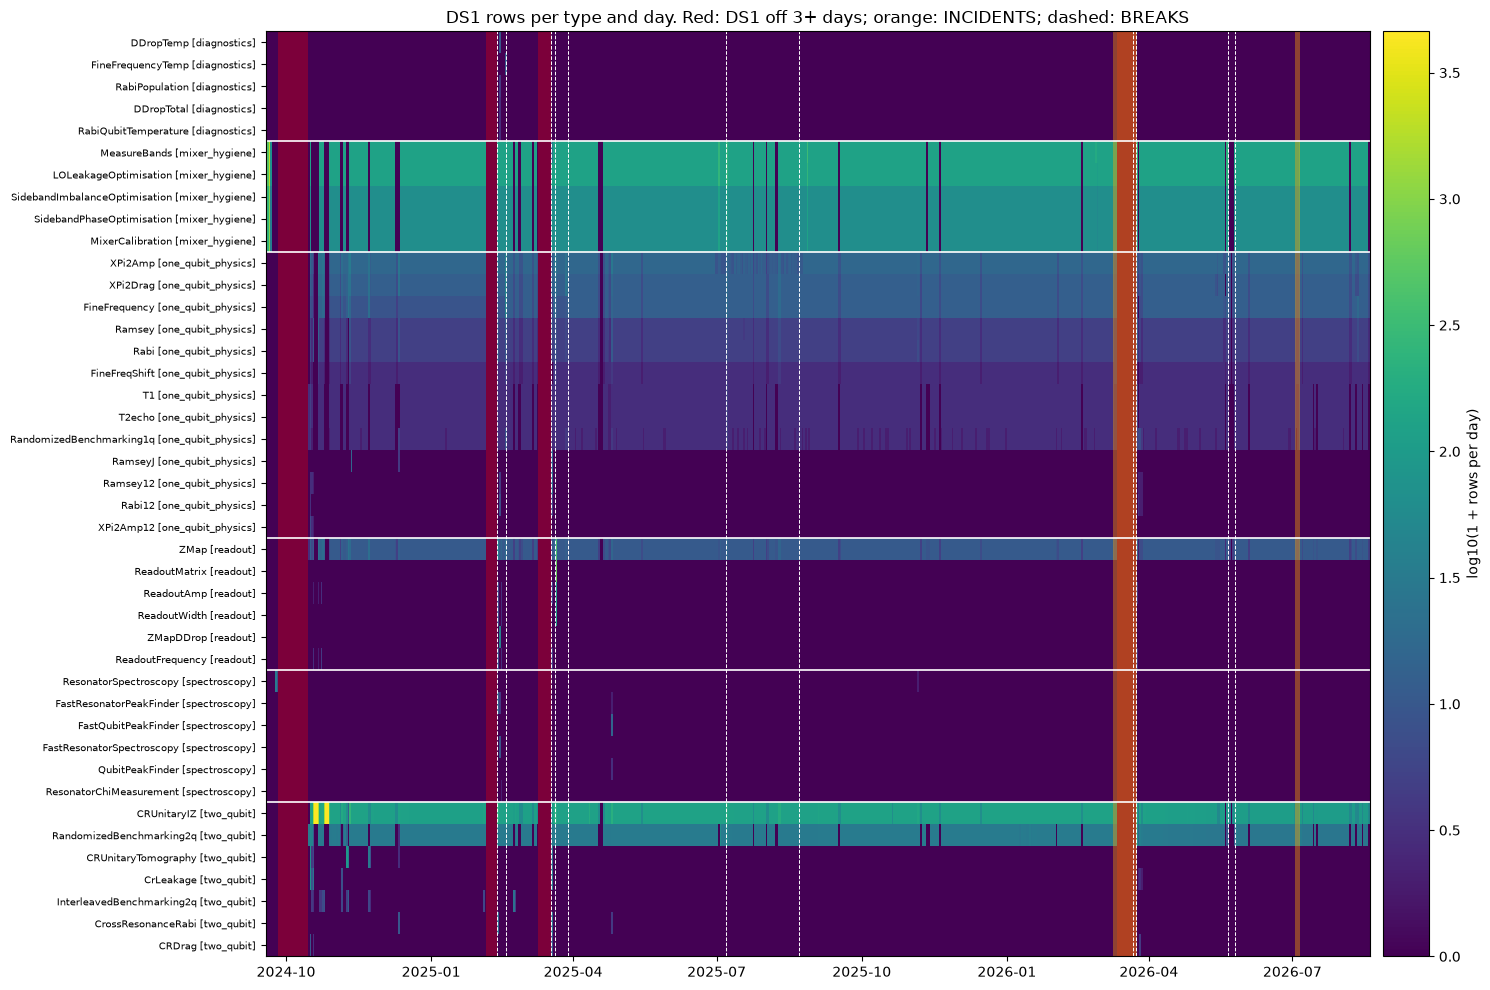

per type: first and last row, active days, share of days active over its own span, rows inside INCIDENTS:


,tier,rows,first,last,active_days,in_incidents,span_days,active_share
measurement_type,,,,,,,,
DDropTemp,diagnostics,9,2025-02-13 12:15:11.410405,2025-02-13 14:46:18.699685,1,0,1,1.000
FineFrequencyTemp,diagnostics,9,2025-02-17 15:04:19.913507,2025-02-17 15:15:19.641043,1,0,1,1.000
RabiPopulation,diagnostics,3,2025-02-13 11:48:55.717289,2025-02-13 14:27:36.004120,1,0,1,1.000
DDropTotal,diagnostics,2,2025-02-13 12:06:53.110114,2025-02-13 12:12:29.673152,1,0,1,1.000
RabiQubitTemperature,diagnostics,2,2025-02-13 11:42:39.626225,2025-02-13 11:45:17.658114,1,0,1,1.000
MeasureBands,mixer_hygiene,81249,2024-09-18 11:53:21.161967,2026-08-17 19:36:13.840253,610,1190,699,0.873
LOLeakageOptimisation,mixer_hygiene,81095,2024-09-18 12:29:32.992622,2026-08-17 19:36:01.531084,610,1152,699,0.873
SidebandImbalanceOptimisation,mixer_hygiene,40619,2024-09-18 12:29:48.313654,2026-08-17 19:36:09.027621,610,576,699,0.873
SidebandPhaseOptimisation,mixer_hygiene,40618,2024-09-18 12:29:37.105610,2026-08-17 19:36:04.756021,610,576,699,0.873


In [8]:
days = pd.DatetimeIndex(m["time_start"].dt.normalize().unique()).sort_values()
off = pd.Series(pd.date_range(days.min(), days.max(), freq="D").difference(days))
off_g = off.groupby((off.diff() != day).cumsum()).agg(["min", "max", "size"])
off_g = off_g[off_g["size"] >= 3].reset_index(drop=True)
off_g["outage"] = [next((f"{a.date()} to {b.date()}" for a, b in periods.OUTAGES if a <= r["max"] and b > r["min"]), "none")
                   for _, r in off_g.iterrows()]
print("DS1 stretches of 3 or more days with no rows, and the OUTAGES entry each overlaps:")
display(off_g)
DS1_OFF = [(r["min"], r["max"] + day) for _, r in off_g.iterrows()]

order = m.groupby("measurement_type").agg(tier=("tier", "first"), rows=("id", "size")).sort_values(
    ["tier", "rows"], ascending=[True, False])
grid = (m.groupby(["measurement_type", m["time_start"].dt.normalize()]).size().unstack(fill_value=0)
        .reindex(index=order.index, columns=pd.date_range(days.min(), days.max(), freq="D"), fill_value=0))
fig, ax = plt.subplots(figsize=(16, 10))
x0, x1 = grid.columns[0], grid.columns[-1] + day
im = ax.imshow(np.log10(1 + grid.to_numpy()), aspect="auto", interpolation="nearest", cmap="viridis",
               extent=[matplotlib.dates.date2num(x0), matplotlib.dates.date2num(x1), len(grid) - 0.5, -0.5])
for a, b in DS1_OFF:
    ax.axvspan(a, b, color="red", alpha=0.3, lw=0)
for a, b in INCIDENT_PERIODS:
    ax.axvspan(a, b, color="orange", alpha=0.4, lw=0)
for b in periods.BREAKS:
    if x0 <= b.at <= x1:
        ax.axvline(b.at, color="white", lw=0.7, ls="--")
edges = np.flatnonzero(order["tier"].to_numpy()[1:] != order["tier"].to_numpy()[:-1]) + 0.5
for e in edges:
    ax.axhline(e, color="white", lw=1.2)
ax.set_yticks(range(len(grid)), [f"{t} [{order.loc[t, 'tier']}]" for t in grid.index], fontsize=7)
ax.xaxis_date()
fig.colorbar(im, ax=ax, label="log10(1 + rows per day)", pad=0.01)
ax.set_title("DS1 rows per type and day. Red: DS1 off 3+ days; orange: INCIDENTS; dashed: BREAKS")
fig.tight_layout()
fig.savefig(FIG / "b3a_ds1_activity.png", dpi=120)
plt.show()

act = m.groupby("measurement_type").agg(
    tier=("tier", "first"), rows=("id", "size"), first=("time_start", "min"), last=("time_start", "max"),
    active_days=("date", "nunique"), in_incidents=("incident", "sum"))
act["span_days"] = (act["last"].dt.normalize() - act["first"].dt.normalize()).dt.days + 1
act["active_share"] = (act["active_days"] / act["span_days"]).round(3)
print("per type: first and last row, active days, share of days active over its own span, rows inside INCIDENTS:")
display(act.loc[order.index])

**Results.**

- DS1 has four stretches of 3 or more days with no rows. Three overlap an `OUTAGES` entry (2025-02-05 to 02-11, 2025-03-10 to 03-17, 2026-03-12 to 03-23). The first, 2024-09-26 to 2024-10-14 (19 days), overlaps none. It lies inside the A4 section 2 gap with no run of any routine from 2024-09-21 to 10-14, and before the `ds1_ds3` study period; `OUTAGES` holds only the gaps from 2025 (A4 section 2).
- The claimed types except CRUnitaryTomography, and the three mixer sub-step types, are active on 0.873 (mixer types) to 0.954 (CRUnitaryIZ) of the days in their own span. The other types are active on at most 14 days (InterleavedBenchmarking2q); ReadoutMatrix is on one day (2025-03-21) and the diagnostics types on 2025-02-13 and 2025-02-17.

Per routine, we group the operating days with no run with claimed rows (outside `OUTAGES` and the off-stretches) into stretches. An operating day runs from 06:00 to 06:00 and is labelled by the date it starts on, so a run that crosses midnight, or starts after midnight, counts for the evening before. A run belongs to the operating day of its first claimed row. We drop the last operating day, which the snapshot cuts off. For each stretch we note how many days still have an `output_info` file and how many have any DS1 row. Cadence counts runs with claimed rows per window and the hours between them.

In [9]:
DAY_START = pd.Timedelta("6h")  # an operating day runs 06:00 to 06:00, so a run after midnight counts for the evening before


def op_day(t: pd.Series) -> pd.Series:
    """The operating day (06:00 to 06:00) of each timestamp, labelled by the date it starts on."""
    return (t - DAY_START).dt.normalize()


cl = m[m["claimed"]]
first_row = cl.groupby(["routine", "run_start"])["time_start"].min().rename("first_row").reset_index()
print("runs with claimed rows by start hour, 00:00 to 09:59 (DAY_START is 06:00):")
display(first_row.assign(h=first_row["run_start"].dt.hour).query("h < 10").pivot_table(
    index="routine", columns="h", values="run_start", aggfunc="size", fill_value=0))
first_row["day"] = op_day(first_row["first_row"])
moved = first_row[first_row["day"] != op_day(first_row["run_start"])]
print("runs whose first claimed row falls on another operating day than the run start (we use the first row's):")
display(moved)

last_row = m["time_start"].max()
kept_days = pd.date_range(op_day(m["time_start"]).min(), op_day(pd.Series([last_row]))[0] - day, freq="D")
print(f"last row {last_row}; its operating day is partial, so the count stops at {kept_days.max().date()}")
kept_days = kept_days[~periods.within(kept_days, *DS1_OFF, *periods.OUTAGES)]
file_days = runs.assign(d=op_day(runs["start"])).groupby("routine")["d"].agg(set)
row_days = set(op_day(m["time_start"]))
rows = []
for routine in SHORT:
    have = set(first_row.loc[first_row["routine"] == routine, "day"])
    miss = pd.Series(sorted(d for d in kept_days if d not in have and d >= min(have)), dtype="datetime64[ns]")
    for _, r in miss.groupby((miss.diff() != day).cumsum()).agg(["min", "max", "size"]).iterrows():
        span_days = pd.date_range(r["min"], r["max"], freq="D")
        rows.append((routine, r["min"].date(), r["max"].date(), r["size"], sum(d in file_days[routine] for d in span_days),
                     sum(d in row_days for d in span_days), bool(periods.within(span_days, *INCIDENT_PERIODS).any())))
miss = pd.DataFrame(rows, columns=["routine", "first", "last", "days", "days_with_run_file", "days_with_ds1_rows",
                                   "in_incident"])
print("operating days outside OUTAGES and DS1 off-stretches, from the routine's first run with claimed rows,",
      "with no such run of it:")
display(miss.groupby("routine").agg(stretches=("days", "size"), days=("days", "sum"),
                                     days_with_run_file=("days_with_run_file", "sum"),
                                     days_with_ds1_rows=("days_with_ds1_rows", "sum"), longest=("days", "max")))
print("stretches of 2 or more days:")
display(miss[miss["days"] >= 2].sort_values(["routine", "first"]).reset_index(drop=True))

rc = cl.groupby(["routine", "run_start"]).size().rename("rows").reset_index()
rc["window"] = rc["run_start"].map(runs.drop_duplicates("start").set_index("start")["window"])
rc["gap_h"] = rc.groupby("routine")["run_start"].diff().dt.total_seconds() / 3600
cad = rc.groupby("routine").agg(runs=("run_start", "size"), morning=("window", lambda s: (s == "morning").sum()),
                                evening=("window", lambda s: (s == "evening").sum()),
                                other=("window", lambda s: (s == "other").sum()), gap_median_h=("gap_h", "median"),
                                gap_p95_h=("gap_h", lambda s: s.quantile(0.95)), gap_max_h=("gap_h", "max")).round(2)
print("runs with claimed rows per routine and window, and hours between consecutive such runs:")
display(cad)

runs with claimed rows by start hour, 00:00 to 09:59 (DAY_START is 06:00):


h,0,1,2,3,4,5,6,7,8,9
routine,,,,,,,,,,
benchmarking,0,2,2,0,1,0,0,0,1,0
calibrate_1q,2,1,1,1,1,0,0,8,605,0
calibrate_2q,37,35,31,30,29,26,24,28,154,497
mixer_calibration,2,1,2,0,1,1,1,0,1,0


runs whose first claimed row falls on another operating day than the run start (we use the first row's):


,routine,run_start,first_row,day
270,benchmarking,2025-08-22 08:26:52,2025-08-21 20:11:39.562803,2025-08-21


last row 2026-08-18 09:12:51.648211; its operating day is partial, so the count stops at 2026-08-17


...

,stretches,days,days_with_run_file,days_with_ds1_rows,longest
routine,,,,,
benchmarking,32,45,1,42,3
calibrate_1q,8,19,3,13,7
calibrate_2q,7,8,4,5,2
mixer_calibration,26,45,1,39,6


stretches of 2 or more days:


,routine,first,last,days,days_with_run_file,days_with_ds1_rows,in_incident
0,benchmarking,2024-10-17,2024-10-19,3,0,3,False
1,benchmarking,2024-10-25,2024-10-27,3,0,3,False
2,benchmarking,2024-11-04,2024-11-05,2,0,2,False
3,benchmarking,2024-11-08,2024-11-09,2,0,2,False
4,benchmarking,2024-12-09,2024-12-10,2,0,2,False
5,benchmarking,2025-02-25,2025-02-26,2,0,2,False
6,benchmarking,2025-04-17,2025-04-19,3,0,1,False
7,benchmarking,2025-11-11,2025-11-12,2,0,2,False
8,benchmarking,2026-05-22,2026-05-24,3,0,2,False
9,calibrate_1q,2024-09-19,2024-09-25,7,0,4,False


runs with claimed rows per routine and window, and hours between consecutive such runs:


,runs,morning,evening,other,gap_median_h,gap_p95_h,gap_max_h
routine,,,,,,,
benchmarking,604,1,590,13,24.00,41.81,309.14
calibrate_1q,1246,614,604,28,12.02,13.55,659.45
calibrate_2q,1954,753,854,347,10.97,13.17,308.27
mixer_calibration,631,2,603,26,24.00,25.10,602.63


**Results.**

- **Day boundary.** No `benchmarking` or `calibrate_1q` run with claimed rows starts between 05:00 and 06:59, and `mixer_calibration` has one at 05:xx and one at 06:xx. So 06:00 separates the evening from the next morning for these routines. `calibrate_2q` starts runs in every hour from 00:00 to 09:59 (24 to 37 an hour before 08:00), so its boundary is arbitrary. One run is moved: the `benchmarking` file stamped 2025-08-22 08:26:52 has its first claimed row at 2025-08-21 20:11. The last row is at 2026-08-18 09:12, so the count stops at 2026-08-17.
- **Operating days with no run with claimed rows**, outside the outages and DS1 gaps: `benchmarking` 45 days in 32 stretches (longest 3), `calibrate_1q` 19 in 8 (longest 7, 2024-09-19 to 09-25), `calibrate_2q` 8 in 7 (longest 2), `mixer_calibration` 45 in 26 (longest 6, 2024-10-16 to 10-21). Of the 45 `benchmarking` days, 42 have DS1 rows and 1 has an `output_info` file. No stretch of 2 or more days is in `INCIDENTS`.
- On 2025-04-18 and 04-19, `calibrate_1q` and `calibrate_2q` have an `output_info` file but no DS1 row at all.
- Cadence (runs with claimed rows; median / p95 hours between them): `calibrate_1q` 614 morning and 604 evening, 12.02 / 13.55; `calibrate_2q` 753 morning, 854 evening and 347 other, 10.97 / 13.17; `benchmarking` 590 evening, 24.00 / 41.81; `mixer_calibration` 603 evening, 24.00 / 25.10.

Per qubit, we count the runs with a claimed row per type; a *reduced* `calibrate_1q` run has fewer qubits with a claimed row than the modal run.

In [10]:
q1 = cl[cl["n_couplings"] == 0].explode("qubits").dropna(subset=["qubits"])
q1["qubit"] = q1["qubits"].astype(int)
print("runs with a claimed row, per qubit and type:")
display(q1.pivot_table(index="qubit", columns="measurement_type", values="run_start", aggfunc="nunique", fill_value=0))
nq = q1[q1["routine"] == "calibrate_1q"].groupby("run_start")["qubit"].nunique()
modal = nq.mode().iloc[0]
print(f"qubits with a claimed row per calibrate_1q run: {nq.value_counts().sort_index().to_dict()} (modal {modal})")
red = nq[nq < modal].rename("qubits").reset_index()
red_g = red.groupby((red["run_start"].diff() > day).cumsum()).agg(
    first=("run_start", "min"), last=("run_start", "max"), runs=("run_start", "size"), qubits=("qubits", lambda s: sorted(set(s))))
red_g["in_incident"] = [bool(periods.within([a, b], *INCIDENT_PERIODS).any()) for a, b in zip(red_g["first"], red_g["last"])]
print("calibrate_1q runs with fewer qubits than the modal count, in stretches (new stretch after a gap over 1 day):")
display(red_g.reset_index(drop=True))

runs with a claimed row, per qubit and type:


measurement_type,FineFreqShift,FineFrequency,MeasureBands,MixerCalibration,Rabi,Ramsey,RandomizedBenchmarking1q,T1,T2echo,XPi2Amp,XPi2Drag,ZMap
qubit,,,,,,,,,,,,
1,0,1231,631,631,1231,1232,572,597,597,1229,1227,1829
2,1244,0,631,631,1245,0,570,604,604,1207,0,1850
4,0,1231,631,631,1231,1232,572,597,597,1229,1227,1829
5,0,1246,631,631,1245,1244,570,604,604,1207,1240,1850
6,0,1231,631,631,1231,1232,572,597,597,1229,1227,1829
7,0,1246,631,631,1245,1244,570,604,604,1207,1240,1850
9,0,1231,631,631,1231,1232,572,597,597,1229,1227,1829
10,0,1246,631,631,1245,1244,570,604,604,1207,1240,1850
11,0,1231,631,631,1231,1232,572,597,597,1229,1227,1829


qubits with a claimed row per calibrate_1q run: {15: 1, 16: 12, 32: 1233} (modal 32)
calibrate_1q runs with fewer qubits than the modal count, in stretches (new stretch after a gap over 1 day):


,first,last,runs,qubits,in_incident
0,2025-04-24 08:45:21,2025-04-25 08:45:22,3,[16],False
1,2026-03-10 08:45:17,2026-03-11 19:43:57,4,"[15, 16]",True
2,2026-07-03 08:45:41,2026-07-05 19:34:00,6,[16],True


**Results.**

- 32 qubits have claimed rows (no Q3, Q8 or Q29). FineFreqShift is claimed on Q2 and Q13 (1,244 runs each) and Q23 (210). Q2 and Q13 have no claimed FineFrequency, Ramsey or XPi2Drag rows; Q23 has FineFrequency 1,021, Ramsey 1,022 and XPi2Drag 1,017 against 1,231, 1,232 and 1,227 for the qubits with the same counts elsewhere. These are the `freq_shift` qubits: B2 section 2 finds 5,535 of the open 1q rows (in the run, no id at a writing step) on them, and FineFreqShift writes the `freq_shift` channel amplitude, not the drive frequency (B2 sections 1 and 3).
- The other qubits split into two sets with different run counts (e.g. FineFrequency 1,231 or 1,246; XPi2Amp 1,229 or 1,207).
- `calibrate_1q` runs by qubits with a claimed row: 32 in 1,233, 16 in 12, 15 in 1. The reduced runs form three stretches: 2025-04-24 to 04-25 (3 runs, 16 qubits, not in `INCIDENTS`), 2026-03-10 to 03-11 (4 runs, in `INCIDENTS`) and 2026-07-03 to 07-05 (6 runs, in `INCIDENTS`).

## 3. Marginals

Then durations, since a slow run can point to hardware trouble. We take `duration_s` quantiles per type, and the monthly median per type for the claimed rows of types with 1,000 or more of them.

In [11]:
dur = m.groupby("measurement_type")["duration_s"].describe(percentiles=[0.05, 0.5, 0.95])
print("duration_s per type:")
display(dur.loc[order.index].round(1))
main = cl.groupby("measurement_type").size().loc[lambda s: s >= 1000].index
med_month = cl[cl["measurement_type"].isin(main)].pivot_table(index="month", columns="measurement_type",
                                                             values="duration_s", aggfunc="median")
print("median duration_s per month of the claimed rows, types with 1000+ claimed rows:")
display(med_month.round(1))
print("ratio of the largest to the smallest monthly median per type:", (med_month.max() / med_month.min()).round(2).to_dict())

duration_s per type:


,count,mean,std,min,5%,50%,95%,max
measurement_type,,,,,,,,
DDropTemp,9.0,41.0,0.1,40.9,40.9,41.0,41.1,41.1
FineFrequencyTemp,9.0,22.6,6.4,13.9,14.0,26.6,26.9,26.9
RabiPopulation,3.0,40.1,0.0,40.0,40.0,40.1,40.1,40.1
DDropTotal,2.0,41.0,0.0,41.0,41.0,41.0,41.0,41.0
RabiQubitTemperature,2.0,75.1,0.0,75.1,75.1,75.1,75.1,75.1
MeasureBands,81249.0,0.5,0.2,0.4,0.4,0.4,1.0,26.3
LOLeakageOptimisation,81095.0,1.6,0.7,1.2,1.3,1.3,3.4,9.3
SidebandImbalanceOptimisation,40619.0,10.1,3.2,3.3,3.8,10.4,17.6,54.3
SidebandPhaseOptimisation,40618.0,10.2,3.2,3.3,3.9,10.4,17.6,77.0


median duration_s per month of the claimed rows, types with 1000+ claimed rows:


measurement_type,CRUnitaryIZ,FineFreqShift,FineFrequency,MeasureBands,MixerCalibration,Rabi,Ramsey,RandomizedBenchmarking1q,RandomizedBenchmarking2q,T1,T2echo,XPi2Amp,XPi2Drag,ZMap
month,,,,,,,,,,,,,,
2024-09,NaN,30.0,51.8,0.4,27.2,26.7,36.7,NaN,NaN,NaN,NaN,58.2,52.5,8.0
2024-10,9.4,29.0,50.7,0.4,34.6,26.6,36.4,3334.6,409.3,102.8,104.0,56.6,51.5,8.1
2024-11,10.4,32.9,64.4,0.4,39.7,33.2,46.2,2182.2,385.8,130.6,131.3,71.5,65.3,8.2
2024-12,9.1,28.5,38.4,0.4,36.0,18.8,27.2,1369.1,282.3,73.8,74.9,43.1,39.3,7.3
2025-01,9.1,28.4,37.8,0.4,29.0,18.5,27.0,1283.7,279.9,72.5,73.3,41.7,39.0,7.2
2025-02,9.2,27.6,37.7,0.4,28.7,18.5,27.1,1341.7,282.1,72.2,73.2,41.6,39.2,7.4
2025-03,9.2,27.6,37.6,0.4,27.6,18.4,27.2,1304.0,282.8,72.3,73.1,41.7,39.2,7.4
2025-04,9.1,27.5,37.6,0.4,27.3,18.1,26.7,1242.4,268.5,71.0,71.9,41.0,38.5,7.1
2025-05,9.2,27.6,38.0,0.4,27.5,18.5,27.2,1331.3,278.8,72.3,73.2,41.7,39.0,7.4


ratio of the largest to the smallest monthly median per type: {'CRUnitaryIZ': 1.25, 'FineFreqShift': 1.32, 'FineFrequency': 1.76, 'MeasureBands': 2.58, 'MixerCalibration': 2.39, 'Rabi': 1.93, 'Ramsey': 1.76, 'RandomizedBenchmarking1q': 3.68, 'RandomizedBenchmarking2q': 2.06, 'T1': 1.88, 'T2echo': 1.87, 'XPi2Amp': 1.78, 'XPi2Drag': 1.7, 'ZMap': 1.15}


**Results.**

- Median `duration_s` of the routine types runs from 0.4 s (MeasureBands) to 1,276.5 s (RB1q); RB2q is 274.8 s, T1 72.1 s and CRUnitaryIZ 9.1 s.
- Monthly medians of the claimed rows are higher in 2024-10 and 2024-11 than from 2024-12 on, for example FineFrequency 50.7 and 64.4 against 38.4, T1 102.8 and 130.6 against 73.8, and RB1q 3,334.6 in 2024-10.
- From 2026-06 the monthly medians step against 2026-05 and stay there to 2026-08: MeasureBands 0.4 to 1.0, MixerCalibration 26.7 to 16.8, RB1q 1,238.3 to 950.5, RB2q 271.9 to 201.7, CRUnitaryIZ 8.6 to 8.3.
- Largest over smallest monthly median: RB1q 3.68, MeasureBands 2.58, MixerCalibration 2.39, RB2q 2.06; ZMap is lowest at 1.15.

A row's duration ratio compares it with rows like it in the same month, so month-level shifts in the median don't count as outliers:

$$r = \frac{d}{\operatorname{median}(d \mid \text{type, stem, target count, month})}$$

over groups of 10 or more rows. We print counts at several ratios with the quantiles over claimed rows, and list rows with $r > 3$ (`RATIO`) as *slow*, by type, month and day.

In [12]:
key = [m["measurement_type"], m["stem"], m["n_qubits"] + m["n_couplings"], m["month"]]
m["dur_ratio"] = m["duration_s"] / m.groupby(key)["duration_s"].transform("median")
n_key = m.groupby(key)["duration_s"].transform("size")
m.loc[n_key < 10, "dur_ratio"] = np.nan
print("rows with a ratio to the median of their type, stem, target count and month (groups of 10+ rows):",
      m["dur_ratio"].notna().sum(), "of", len(m))
print("rows above each ratio, by class:")
display(pd.DataFrame({r: m.loc[m["dur_ratio"] > r, "row_class"].value_counts() for r in (1.5, 2, 3, 5)}).fillna(0).astype(int))
print("quantiles of the ratio over claimed rows:",
      m.loc[m["claimed"], "dur_ratio"].quantile([0.5, 0.99, 0.999, 0.9999]).round(2).to_dict())
RATIO = 3
slow = m[m["dur_ratio"] > RATIO]
print(f"slow rows (ratio > {RATIO}) per type:")
display(slow.groupby("measurement_type").agg(rows=("id", "size"), median_ratio=("dur_ratio", "median"),
                                             max_s=("duration_s", "max"), in_incidents=("incident", "sum"),
                                             claimed=("claimed", "sum"))
        .join(m.groupby("measurement_type").size().rename("type_rows")).sort_values("rows", ascending=False).round(2))
print("slow rows per month:")
display(slow.groupby("month").size().to_frame("rows").T)
by_day = slow.groupby("date").agg(rows=("id", "size"), runs=("slot_start", "nunique"),
                                  types=("measurement_type", lambda s: ", ".join(s.value_counts().index[:3])),
                                  in_incidents=("incident", "sum"))
print("days with 5 or more slow rows:")
display(by_day[by_day["rows"] >= 5])
print("the 15 slowest rows by ratio:")
display(slow.nlargest(15, "dur_ratio")[["time_start", "measurement_name", "duration_s", "dur_ratio", "row_class", "incident"]])

rows with a ratio to the median of their type, stem, target count and month (groups of 10+ rows): 443137 of 444080
rows above each ratio, by class:


,1.5,2.0,3.0,5.0
row_class,,,,
claimed,2929,1403,100,37
"in run, claimed type",149,60,14,11
"in run, other",3882,1061,47,6
outside runs,828,556,172,18


quantiles of the ratio over claimed rows: {0.5: 1.0, 0.99: 1.59, 0.999: 2.71, 0.9999: 6.72}
slow rows (ratio > 3) per type:


,rows,median_ratio,max_s,in_incidents,claimed,type_rows
measurement_type,,,,,,
CRUnitaryIZ,144,4.14,88.97,0,17,98812
MeasureBands,81,3.72,26.28,0,61,81249
LOLeakageOptimisation,65,3.88,9.26,0,0,81095
MixerCalibration,17,3.23,173.48,0,11,40540
FastQubitPeakFinder,6,9.91,3.30,0,0,14
ZMap,5,3.99,37.97,0,5,6687
FastResonatorPeakFinder,4,9.59,33.36,0,0,16
SidebandPhaseOptimisation,4,5.93,77.03,0,0,40618
Ramsey,3,6.12,166.04,0,3,2525


slow rows per month:


month,2025-02,2025-03,2025-04,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
rows,77,37,7,2,4,16,8,9,10,2,13,117,18,6,7


days with 5 or more slow rows:


,rows,runs,types,in_incidents
date,,,,
2025-02-03,12,0,CRUnitaryIZ,0
2025-02-22,52,0,CRUnitaryIZ,0
2025-02-23,9,0,CRUnitaryIZ,0
2025-03-18,37,0,CRUnitaryIZ,0
2025-04-25,7,0,"FastQubitPeakFinder, CRUnitaryIZ",0
2025-11-19,11,2,"CRUnitaryIZ, XPi2Amp, ZMap",0
2026-02-26,9,0,MeasureBands,0
2026-05-20,46,2,"LOLeakageOptimisation, MixerCalibration, MeasureBands",0
2026-05-21,19,2,"MeasureBands, LOLeakageOptimisation, MixerCalibration",0


the 15 slowest rows by ratio:


,time_start,measurement_name,duration_s,dur_ratio,row_class,incident
99868,2025-02-12 14:32:45.008924,res_peak,33.363382,95.698540,outside runs,False
439640,2026-08-10 13:34:37.896752,measure_bands_after_cal,26.282950,27.185003,claimed,False
342770,2026-02-26 12:24:10.561068,measure_bands_before_cal,4.909554,13.048753,outside runs,False
325489,2026-01-30 19:30:24.759584,measure_bands_before_cal,4.753964,12.587814,claimed,False
342743,2026-02-26 12:10:36.916064,measure_bands_before_cal,4.673932,12.422510,outside runs,False
372068,2026-04-24 19:31:46.513932,measure_bands_after_cal,4.270922,11.702888,claimed,False
388244,2026-05-20 20:13:33.317075,measure_bands_before_cal,4.333172,11.294170,claimed,False
404106,2026-06-16 09:22:51.387777,cr_u_C7-T6,88.967488,10.768347,"in run, claimed type",False
404101,2026-06-16 09:15:57.469954,cr_u_C27-T34,88.919897,10.762587,claimed,False
404105,2026-06-16 09:21:22.216067,cr_u_C6-T5,88.711458,10.737358,claimed,False


**Results.**

- 443,137 of 444,080 rows have a duration ratio. Over claimed rows its quantiles are 1.0 (0.5), 1.59 (0.99), 2.71 (0.999) and 6.72 (0.9999), so `RATIO` = 3 sits between the 0.999 and 0.9999 quantiles.
- Rows above 3: claimed 100, `in run, claimed type` 14, `in run, other` 47, `outside runs` 172. No slow row is inside `INCIDENTS`. By type: CRUnitaryIZ 144 (17 claimed), MeasureBands 81, LOLeakageOptimisation 65, MixerCalibration 17.
- Slow rows by month peak in 2026-05 (117) and 2025-02 (77). The days with the most are 2025-02-22 (52, CRUnitaryIZ, no run), 2026-05-20 (46, mixer types, 2 runs) and 2025-03-18 (37, CRUnitaryIZ, no run). The mixer types are also slow on 2026-05-21, 05-26, 05-27 and 05-29.
- The two slowest rows are `res_peak` on 2025-02-12 (ratio 95.7, outside runs) and a claimed `measure_bands_after_cal` on 2026-08-10 (27.2). Four `cr_u` rows on 2026-06-16 between 09:15 and 09:22 take 88.4 to 89.0 s, ratios 10.7 to 10.8.

## 4. Noise floor: unlinked rows

The noise floor itself lives in the payloads (B3c, B3d), so here we check the index side instead: which attempted rows never got linked to the run map. The *attempted* rows are the claimed and `in run, claimed type` rows (section 1); the unclaimed types (mixer sub-steps, readout and the others in A3) aren't attempts. An unclaimed attempted row gets the first class that fits: `2q coupling claimed by another row` (a `calibrate_2q` row whose couplings all have a claimed row in the same run), `every target warned` (all its qubits or couplings are named in a matching `output_info` warning of that run, `WARN`), else `unlinked`. Shares are split by `INCIDENTS`.

The unlinked share isn't a failure rate, though - a row with an id can still be a warned or rejected attempt. So we also count the attempted (run, target) pairs that a warning names, per type; B2 has the reject shares from the controller side.

Then missing steps: an expected name with no row at all in a run. Expected names have a stem in the routine's call order (section 1) and appear in at least `MIN_SHARE` of the `WINDOW` non-empty runs of that routine centred on the run. Runs with no attempted row are listed on their own.

In [13]:
WARN = {
    "FineFrequency": re.compile(r"Fine-frequency calibration of Q(\d+) out of spec"),
    "FineFreqShift": re.compile(r"Fine-frequency shift calibration of Q(\d+) out of spec"),
    "XPi2Amp": re.compile(r"Amplitude calibration out of spec(?: for|:) Q(\d+)"),
    "XPi2Drag": re.compile(r"DRAG calibration out of spec for Q(\d+)"),
    "Rabi": re.compile(r"Rabi calibration of Q(\d+) out of spec"),
    "T1": re.compile(r"Did not return a T1 time for Q(\d+)"),
    "T2echo": re.compile(r"Did not return a T2e time for Q(\d+)"),
    "RandomizedBenchmarking1q": re.compile(r"Did not return a 1Q gate fidelity for Q(\d+)"),
    "RandomizedBenchmarking2q": re.compile(r"Did not return a 2Q gate fidelity for C(\d+)-T(\d+)"),
    "CRUnitaryIZ": re.compile(r"(?:Reverting calibration for|Amplitude too high on qubit pair) \((\d+), (\d+)\)"),
}
warned = {}
templates = []
for _, start, routine, oi in iter_files(OUTPUT_INFO):
    for w in map(str, oi.get("warnings") or []):
        tpl = re.sub(r"\d+(\.\d+)?(e[+-]?\d+)?", "#", w)
        templates.append((routine, tpl[:90], next((t for t, rx in WARN.items() if rx.search(w)), "")))
        for t, rx in WARN.items():
            if mt := rx.search(w):
                target = f"C{mt[1]}-T{mt[2]}" if rx.groups == 2 else f"Q{mt[1]}"
                warned.setdefault((routine, pd.Timestamp(start), t), set()).add(target)
print("warning templates in output_info (numbers as #) and the WARN type whose pattern matches them:")
display(pd.DataFrame(templates, columns=["routine", "template", "matched_type"]).value_counts().rename("warnings").reset_index())

warning templates in output_info (numbers as #) and the WARN type whose pattern matches them:


,routine,template,matched_type,warnings
0,calibrate_1q,Amplitude calibration out of spec for Q# with N=#,XPi2Amp,12574
1,benchmarking,Fit quality for Q# is too low: #%.,,3607
2,calibrate_1q,Fine-frequency calibration of Q# out of spec with delay #us,FineFrequency,1983
3,calibrate_2q,"Reverting calibration for (#, #) with N=# due to high amplitude",CRUnitaryIZ,1931
4,calibrate_1q,DRAG calibration out of spec for Q# with N=#,XPi2Drag,1341
5,benchmarking,Fit quality for C#-T# is too low: #%. Coupling quality factor set to #.,,1298
6,calibrate_1q,Q# pulse DRAG out of spec - resetting to zero,,128
7,benchmarking,Fit quality for C#-T# is too low: #%. Coupling quality factor not updated.,,82
8,benchmarking,Fit quality for C#-T# is too low: -#%. Coupling quality factor set to #.,,54
9,calibrate_1q,Fine-frequency shift calibration of Q# out of spec with delay #us and amp ra...,FineFreqShift,25


**Results.**

- `output_info` has 16 warning templates. The largest are `calibrate_1q` "Amplitude calibration out of spec" (12,574, XPi2Amp), `benchmarking` "Fit quality for Q# is too low" (3,607, no matched type), "Fine-frequency calibration … out of spec" (1,983) and `calibrate_2q` "Reverting calibration … due to high amplitude" (1,931).

An unclaimed attempted row gets the first class that fits: `2q coupling claimed by another row` (a `calibrate_2q` row whose couplings all have a claimed row in the same run), `every target warned` (all its qubits or couplings are named in a matching `output_info` warning of that run, `WARN`), else `unlinked`. Shares are split by `INCIDENTS`.

The unlinked share isn't a failure rate, though - a row with an id can still be a warned or rejected attempt. So we also count the attempted (run, target) pairs that a warning names, per type; B2 has the reject shares from the controller side.

In [14]:
att = m[m["row_class"].isin(["claimed", "in run, claimed type"])].copy()
att["targets"] = [targets(r) for r in att[["couplings", "qubits", "n_couplings"]].itertuples()]
c2 = att[att["claimed"] & (att["routine"] == "calibrate_2q")]
claimed_2q = {(s, c): t for s, ts, t in zip(c2["slot_start"], c2["targets"], c2["time_start"]) for c in ts}


def link_class(r) -> str:
    """Why an in-run row of a claimed type has no claiming id, from the run's other ids and its warnings."""
    if r.claimed:
        return "claimed"
    if r.slot_routine == "calibrate_2q" and all((r.slot_start, c) in claimed_2q for c in r.targets):
        return "2q coupling claimed by another row"
    if r.targets and r.targets <= warned.get((r.slot_routine, r.slot_start, r.measurement_type), set()):
        return "every target warned"
    return "unlinked"


att["link_class"] = [link_class(r) for r in att.itertuples()]
sup = att[att["link_class"] == "2q coupling claimed by another row"]
earlier = [all(t < claimed_2q[(s, c)] for c in ts) for s, ts, t in zip(sup["slot_start"], sup["targets"], sup["time_start"])]
src_2q = (ROUTINES / "calibration_routines" / "scripts" / "calibrate_2q.py").read_text().splitlines()
print("calibrate_2q at routines HEAD:", *[f"  {i + 1}: {s.strip()}" for i, s in enumerate(src_2q)
                                         if re.search(r"def run_calibrate_2q|for N in|result_ids\[f'C", s)], sep="\n")
print(f"'2q coupling claimed by another row': {np.sum(earlier)} of {len(sup)} start before the claimed row")
fc = att.pivot_table(index=["measurement_type", "incident"], columns="link_class", values="id", aggfunc="size",
                     fill_value=0)
fc["attempted"] = fc.sum(axis=1)
fc["unlinked_share"] = (fc["unlinked"] / fc["attempted"]).round(5)
print("in-run rows of the claimed types by link class, outside (False) and inside (True) INCIDENTS:")
display(fc)
tot = att.groupby("incident")["link_class"].value_counts().unstack(fill_value=0)
tot["unlinked_share"] = (tot["unlinked"] / tot.sum(axis=1)).round(5)
print("all claimed types pooled:")
display(tot)

tw = (att[["slot_routine", "slot_start", "measurement_type", "targets", "incident"]].explode("targets")
      .dropna(subset=["targets"]).drop_duplicates(["slot_routine", "slot_start", "measurement_type", "targets"]))
tw["warned"] = [t in warned.get((r, s, ty), ()) for r, s, ty, t in
                zip(tw["slot_routine"], tw["slot_start"], tw["measurement_type"], tw["targets"])]
print("attempted (run, qubit or coupling) pairs per type, and the share a WARN warning of that run names:")
display(tw.groupby(["measurement_type", "incident"])["warned"].agg(pairs="size", warned="sum", share="mean")
        .unstack().round(5))

calibrate_2q at routines HEAD:
  17: def run_calibrate_2q(env, cr_u_N=[1,2], cr_u_shots=1000):
  84: for N in cr_u_N:
  96: result_ids[f'C{c}_T{t}'] = result.id
'2q coupling claimed by another row': 36154 of 36411 start before the claimed row
in-run rows of the claimed types by link class, outside (False) and inside (True) INCIDENTS:


link_class                         2q coupling claimed by another row  claimed  every target warned  unlinked  attempted  unlinked_share
measurement_type         incident                                                                                                       
CRUnitaryIZ              False                                  36285    58988                 1658       493      97424         0.00506
                         True                                      94      104                   50       220        468         0.47009
CRUnitaryTomography      False                                     32       32                    0         0         64         0.00000
FineFreqShift            False                                      0     1231                    0         0       1231         0.00000
                         True                                       0       13                    1         0         14         0.00000
FineFrequency            False                                      0     6897                    0         0       6897         0.00000
                         True                                       0       54                    0         0         54         0.00000
MeasureBands             False                                      0    79614                    0         0      79614         0.00000
                         True                                       0     1152                    0         0       1152         0.00000
MixerCalibration         False                                      0    39793                    0         0      39793         0.00000
                         True                                       0      576                    0         0        576         0.00000
Rabi                     False                                      0     2458                    0         0       2458         0.00000
                         True                                       0       18                    0         0         18         0.00000
Ramsey                   False                                      0     2458                    0         0       2458         0.00000
                         True                                       0       18                    0         0         18         0.00000
RandomizedBenchmarking1q False                                      0     1134                    0         0       1134         0.00000
                         True                                       0        8                    0         0          8         0.00000
RandomizedBenchmarking2q False                                      0    18231                    0         0      18231         0.00000
                         True                                       0      192                    0         0        192         0.00000
T1                       False                                      0     1192                    0         0       1192         0.00000
                         True                                       0        9                    0         0          9         0.00000
T2echo                   False                                      0     1192                    0         0       1192         0.00000
                         True                                       0        9                    0         0          9         0.00000
XPi2Amp                  False                                      0     9489                   17         0       9506         0.00000
                         True                                       0       67                    5         0         72         0.00000
XPi2Drag                 False                                      0     7343                    0         0       7343         0.00000
                         True                                       0       53                    1         0         54         0.00000
ZMap                     Fa

all claimed types pooled:


link_class,2q coupling claimed by another row,claimed,every target warned,unlinked,unlinked_share
incident,,,,,
False,36317,236150,1675,493,0.00180
True,94,2318,57,220,0.08181


attempted (run, qubit or coupling) pairs per type, and the share a WARN warning of that run names:


pairs          warned           share         
incident                    False  True     False  True     False    True 
measurement_type                                                          
CRUnitaryIZ               60310.0  349.0   1052.0   27.0  0.01744  0.07736
CRUnitaryTomography          32.0    NaN      0.0    NaN  0.00000      NaN
FineFreqShift              2672.0   28.0     19.0    6.0  0.00711  0.21429
FineFrequency             36670.0  260.0   1768.0  180.0  0.04821  0.69231
MeasureBands              19904.0  288.0      0.0    0.0  0.00000  0.00000
MixerCalibration          19904.0  288.0      0.0    0.0  0.00000  0.00000
Rabi                      39324.0  278.0     16.0    3.0  0.00041  0.01079
Ramsey                    36658.0  260.0      0.0    0.0  0.00000  0.00000
RandomizedBenchmarking1q  18150.0  124.0      0.0    0.0  0.00000  0.00000
RandomizedBenchmarking2q  18231.0  192.0     17.0    0.0  0.00093  0.00000
T1                        19070.0  139.0      0.0    0.0  0.00000  0.00000
T2echo                    19070.0  139.0      0.0    0.0  0.00000  0.00000
XPi2Amp                   38735.0  278.0  12054.0  246.0  0.31119  0.88489
XPi2Drag                  36522.0  260.0   1150.0  183.0  0.03149  0.70385
ZMap                      58426.0  417.0      0.0    0.0  0.00000  0.00000

**Results.**

- `run_calibrate_2q` at HEAD loops over `cr_u_N=[1,2]` and stores `result_ids[f'C{c}_T{t}'] = result.id` inside the loop (lines 17, 84, 96), and 36,154 of the 36,411 `2q coupling claimed by another row` rows start before the claimed row of their coupling. So these are earlier-N rows whose id got overwritten.
- Pooled over the claimed types, the unlinked share of attempted rows is 0.00180 outside `INCIDENTS` (493 rows) and 0.08181 inside (220 rows). `every target warned` covers 1,675 rows outside and 57 inside.
- Every unlinked row is CRUnitaryIZ: 0.00506 of its attempted rows outside `INCIDENTS` (493) and 0.47009 inside (220 of 468). Every other type has none.
- Warnings name far more attempts than that. Outside `INCIDENTS`, the warned share of attempted (run, target) pairs is 0.31119 for XPi2Amp (of 38,735 pairs), 0.04821 FineFrequency, 0.03149 XPi2Drag, 0.01744 CRUnitaryIZ, 0.00711 FineFreqShift, 0.00093 RB2q, 0.00041 Rabi and 0 for the rest. Inside, XPi2Amp is at 0.88489, XPi2Drag 0.70385, FineFrequency 0.69231, FineFreqShift 0.21429, CRUnitaryIZ 0.07736 and Rabi 0.01079. XPi2Amp has no unlinked rows at all, so the unlinked share says nothing about these warnings.

Next, where the unlinked rows outside `INCIDENTS` sit, by stem, quarter, coupling and run.


In [15]:
un = att[(att["link_class"] == "unlinked") & ~att["incident"]]
un_q = un.assign(quarter=un["time_start"].dt.to_period("Q").astype(str))
print("unlinked rows outside INCIDENTS by stem and quarter:")
display(un_q.pivot_table(index=["slot_routine", "stem"], columns="quarter", values="id", aggfunc="size", fill_value=0)
        .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False))
per_run = un.groupby(["slot_routine", "slot_start"]).agg(rows=("id", "size"), names=("measurement_name", lambda s: ", ".join(sorted(set(s))[:4])))
print("runs with unlinked rows outside INCIDENTS, by rows per run:", per_run["rows"].value_counts().sort_index().to_dict())
print("the 15 runs with the most unlinked rows:")
display(per_run.sort_values("rows", ascending=False).head(15))
for st_name in ("cr_u", "cr_u_stability"):
    print(f"unlinked {st_name} rows outside INCIDENTS by coupling:",
          un.loc[un["stem"] == st_name, "measurement_name"].str.extract(r"(C\d+-T\d+)")[0].value_counts().head(10).to_dict())

unlinked rows outside INCIDENTS by stem and quarter:


quarter                      2024Q4  2025Q1  2025Q2  2026Q2  2026Q3  total
slot_routine stem                                                         
calibrate_2q cr_u_stability     379       0       0       0       0    379
             cr_u                19      34      34       4      23    114

runs with unlinked rows outside INCIDENTS, by rows per run: {1: 473, 2: 10}
the 15 runs with the most unlinked rows:


rows                       names
slot_routine slot_start                                           
calibrate_2q 2026-08-16 09:03:30     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-16 19:54:02     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-17 19:58:14     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-18 09:03:54     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-14 09:04:11     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-13 20:04:50     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-12 20:02:05     2   cr_u_C17-T16, cr_u_C7-T16
             2025-01-23 08:18:04     2  cr_u_C22-T21, cr_u_C28-T21
             2026-08-11 20:04:28     2   cr_u_C17-T16, cr_u_C7-T16
             2026-08-12 09:03:36     2   cr_u_C17-T16, cr_u_C7-T16
             2024-10-20 20:50:15     1       cr_u_stabilityC24-T23
             2024-10-20 21:00:16     1       cr_u_stabilityC24-T23
             2024-10-20 21:10:16     1       cr_u_stabilityC24-T23
             2024-10-20 20:40:16     1       cr_u_stabilityC24-T23
             2024-10-20 21:20:16     1       cr_u_stabilityC24-T23

unlinked cr_u rows outside INCIDENTS by coupling: {'C24-T23': 77, 'C7-T16': 15, 'C17-T16': 11, 'C28-T21': 3, 'C22-T21': 3, 'C19-T11': 2, 'C10-T11': 2, 'C14-T15': 1}
unlinked cr_u_stability rows outside INCIDENTS by coupling: {'C24-T23': 379}


**Results.**

- Outside `INCIDENTS`, the unlinked rows are `cr_u_stability` (379, all 2024Q4) and `cr_u` (114). All 379 `cr_u_stability` rows are C24-T23, and C24-T23 also has 77 of the 114 `cr_u` rows; next are C7-T16 (15) and C17-T16 (11).
- 473 runs have one unlinked row and 10 have two, all `calibrate_2q`. C7-T16 and C17-T16 are unlinked together in nine runs from 2026-08-11 to 2026-08-18, and C22-T21 and C28-T21 on 2025-01-23.

Then missing steps: an expected name with no row at all in a run. Expected names have a stem in the routine's call order (section 1) and appear in at least `MIN_SHARE` of the `WINDOW` non-empty runs of that routine centred on the run. Runs with no attempted row are listed on their own.


In [16]:
MIN_SHARE = 0.5
WINDOW = 21
present = att.groupby(["slot_routine", "slot_start"])["measurement_name"].agg(set)
slot_runs = slots[slots["slot_start"] >= m["time_start"].min()].set_index(["slot_routine", "slot_start"])
slot_runs = slot_runs.assign(names=present.reindex(slot_runs.index).apply(lambda s: s if isinstance(s, set) else set()))
slot_runs["incident"] = periods.within(slot_runs.index.get_level_values("slot_start"), *INCIDENT_PERIODS)
empty = slot_runs[slot_runs["names"].map(len) == 0]
print(f"runs from the first DS1 row with no claimed or 'in run, claimed type' row: {len(empty)}")
display(empty.reset_index()[["slot_routine", "slot_start", "slot_window", "n_result_ids", "incident"]])
live = slot_runs[slot_runs["names"].map(len) > 0]
rows = []
for routine, d in live.groupby(level=0):
    pres = pd.DataFrame([dict.fromkeys(s, True) for s in d["names"]], index=d.index.get_level_values(1))
    pres = pres.loc[:, [re.sub(r"_\d+$", "", stem(n)) in CODE[routine] for n in pres.columns]].notna()
    expected = pres.astype(float).rolling(WINDOW, center=True, min_periods=WINDOW // 2 + 1).mean() >= MIN_SHARE
    miss = (expected & ~pres).stack().loc[lambda s: s].index.to_frame(index=False, name=["slot_start", "name"])
    miss["routine"] = routine
    rows.append((routine, expected.to_numpy().sum(), miss))
ms = pd.concat([r[2] for r in rows], ignore_index=True)
ms["stem"] = ms["name"].map(stem)
ms["incident"] = periods.within(ms["slot_start"], *INCIDENT_PERIODS)
print(f"expected name = a name whose stem is in the routine's call order (section 1), present in {MIN_SHARE:.0%}+ of the "
      f"{WINDOW} non-empty runs of the routine centred on the run; expected (run, name) pairs:", {r: int(n) for r, n, _ in rows})
print("expected names with no row in the run, by stem, outside (False) and inside (True) INCIDENTS:")
display(ms.pivot_table(index=["routine", "stem"], columns="incident", values="name", aggfunc="size", fill_value=0))
q = ms[~ms["incident"]].assign(quarter=lambda d: d["slot_start"].dt.to_period("Q").astype(str))
by_name = q.pivot_table(index=["routine", "name"], columns="quarter", values="slot_start", aggfunc="size", fill_value=0)
by_name = by_name.assign(total=by_name.sum(axis=1), first=q.groupby(["routine", "name"])["slot_start"].min(),
                         last=q.groupby(["routine", "name"])["slot_start"].max())
print("names missing from 5 or more runs outside INCIDENTS, by quarter:")
display(by_name[by_name["total"] >= 5].sort_values("total", ascending=False))
per_run_miss = q.groupby(["routine", "slot_start"])["name"].size()
print("runs outside INCIDENTS by number of missing names:", per_run_miss.groupby(level=0).value_counts().sort_index().to_dict())

runs from the first DS1 row with no claimed or 'in run, claimed type' row: 40


,slot_routine,slot_start,slot_window,n_result_ids,incident
0,calibrate_2q,2024-10-18 15:50:16,other,0,False
1,calibrate_1q,2024-11-04 08:00:17,morning,0,False
2,calibrate_2q,2024-11-04 08:01:00,morning,0,False
3,calibrate_1q,2025-02-05 08:00:27,morning,0,False
4,calibrate_2q,2025-02-05 08:01:13,morning,0,False
5,calibrate_1q,2025-02-06 08:00:28,morning,0,False
6,calibrate_2q,2025-02-06 08:01:14,morning,0,False
7,calibrate_1q,2025-02-27 08:00:21,morning,0,False
8,calibrate_2q,2025-02-27 08:01:07,morning,0,False
9,calibrate_1q,2025-03-07 08:00:20,morning,0,False


expected name = a name whose stem is in the routine's call order (section 1), present in 50%+ of the 21 non-empty runs of the routine centred on the run; expected (run, name) pairs: {'benchmarking': 23269, 'calibrate_1q': 16194, 'calibrate_2q': 37270, 'mixer_calibration': 1893}
expected names with no row in the run, by stem, outside (False) and inside (True) INCIDENTS:


incident                        False  True 
routine      stem                           
benchmarking rb1q                  60      6
             rb2q                  14     12
             t1                     2      5
             t2e                    2      5
             zmap                   2      5
calibrate_1q fine_freq              5     10
             fine_freq_shift_0      1      0
             rabi                   6     10
             ramsey                 6     10
             xpi2_amp              42     10
             xpi2_drag             15     10
             zmap                   4     10
calibrate_2q cr_u                  19     56

names missing from 5 or more runs outside INCIDENTS, by quarter:


quarter                        2024Q4  2025Q1  2025Q2  2025Q3  2025Q4  2026Q1  2026Q2  2026Q3  total               first                last
routine      name                                                                                                                           
calibrate_1q xpi2_amp_group2        0       0       2      28       0       0       2       3     35 2025-06-30 08:45:24 2026-08-11 08:45:42
benchmarking rb1q_group2            2       0       5       5      10       4       7       0     33 2024-10-16 16:32:41 2026-06-29 20:06:56
             rb1q_group1            2       2       4       7       5       2       3       2     27 2024-10-28 19:35:38 2026-08-02 20:03:01
calibrate_2q cr_u_C10-T11           0       0       0       0       0       0      11       0     11 2026-04-13 20:06:30 2026-04-26 20:05:30
calibrate_1q xpi2_drag_group1       0       0       4       0       0       0       2       3      9 2025-04-23 19:43:08 2026-08-11 08:45:42
             xpi2_amp_group1        0       0       4       0       0       0       1       2      7 2025-04-23 19:43:08 2026-08-11 08:45:42
             xpi2_drag_group2       0       0       0       0       0       0       3       3      6 2026-05-13 08:45:17 2026-08-11 08:45:42
             rabi_group1            0       0       4       0       0       0       1       0      5 2025-04-23 19:43:08 2026-05-18 08:45:17
             fine_freq_group1       0       0       4       0       0       0       1       0      5 2025-04-23 19:43:08 2026-05-18 08:45:17

runs outside INCIDENTS by number of missing names: {('benchmarking', 1): 59, ('benchmarking', 5): 3, ('benchmarking', 6): 1, ('calibrate_1q', 1): 32, ('calibrate_1q', 2): 1, ('calibrate_1q', 3): 2, ('calibrate_1q', 4): 1, ('calibrate_1q', 5): 2, ('calibrate_1q', 6): 3, ('calibrate_1q', 7): 1, ('calibrate_2q', 1): 16, ('calibrate_2q', 3): 1}


**Results.**

- 40 runs from the first DS1 row have no attempted row, none in `INCIDENTS`, and all have 0 result ids. Most are a `calibrate_1q` and `calibrate_2q` pair in the morning window.
- Expected names are present in 50%+ of the 21 non-empty runs around each run. The expected pairs are 23,269, 16,194, 37,270 and 1,893 per routine, and no `mixer_calibration` name is missing. Missing ones, outside and inside `INCIDENTS`:
  - `benchmarking`: `rb1q` 60 and 6, `rb2q` 14 and 12, and `t1`, `t2e` and `zmap` 2 and 5 each.
  - `calibrate_1q`: `xpi2_amp` 42 and 10, `xpi2_drag` 15 and 10, `ramsey` and `rabi` 6 and 10 each, `fine_freq` 5 and 10, `zmap` 4 and 10, `fine_freq_shift_0` 1 and 0.
  - `calibrate_2q`: `cr_u` 19 and 56.
- Names missing from 5 or more runs outside `INCIDENTS`: `xpi2_amp_group2` 35 (28 in 2025Q3, first 2025-06-30), `rb1q_group2` 33 and `rb1q_group1` 27 (spread over 2024Q4 to 2026Q3), `cr_u_C10-T11` 11 (2026-04-13 to 2026-04-26). The `calibrate_1q` group1 names each miss 4 runs in 2025Q2 from 2025-04-23 19:43:08.
- Most runs with a missing name miss one: `benchmarking` 59, `calibrate_1q` 32, `calibrate_2q` 16.


## 5. Stationarity screen

Last, does what the routines run stay put? Attempted rows per run per stem form a series per routine, and a *change* is a stretch of `MIN_RUNS` or more runs with an equal count that differs from the stretch before it. The series can wander in between, so the change lies somewhere from the first run after the previous stretch (`from_run`) to the first run of the new one (`first_run`). A change is *matched* when a `periods.py` event falls within `MATCH_DAYS` of that window. The register holds the starts and ends of `OUTAGES`, `INCIDENTS`, `F01_FLAGS`, `THERMAL_CYCLES`, `DS4_GAPS` and `SETTLING`, plus `BREAKS`, `UNTRACKED_DS2` and `UNTRACKED_DS2_OTHER`.

A long window catches an event more easily, so each change $c$ spanning $k_c$ runs gets a chance $p_c$: the share of all windows of $k_c$ runs of that routine that hold an event. The matches we'd expect by chance are then

$$E = \sum_c p_c .$$

For each `cr_u` and `rb2q` change, we list the couplings with a row in at least half of the `MIN_RUNS` runs before the window and under half after it, or the other way round. A coupling whose `cr_u` rows stop is *reversed* if its reverse (target and control swapped) starts later; for the rest, we set the last `cr_u` row against the A3 no-trace `calibrate_2q` amp rows (no id, no warning, no new value, non-empty run) listed afterwards. Days with `outside runs` rows get the nearest register event, with the share of all DS1 days near an event as their chance. We finish with the monthly mix per tier and class.

In [17]:
per_run_stem = att.groupby(["slot_routine", "slot_start", "stem"]).size().rename("rows").reset_index()
grid_rs = per_run_stem.pivot_table(index=["slot_routine", "slot_start"], columns="stem", values="rows", fill_value=0)
MIN_RUNS = 10
MATCH_DAYS = 2
MD = pd.Timedelta(days=MATCH_DAYS)
print(f"MATCH_DAYS = {MATCH_DAYS}: the largest p95 gap between consecutive runs of a routine is "
      f"{cad['gap_p95_h'].max()} h (section 2)")
ev = pd.DataFrame(
    [(b.at, f"break: {b.what}") for b in periods.BREAKS]
    + [(t, f"outage {k}") for p in periods.OUTAGES for t, k in zip(p, ("start", "end"))]
    + [(t, f"incident {k}: {i.what}") for i in periods.INCIDENTS for t, k in zip(i.period, ("start", "end"))]
    + [(t, f"f01 flag {k}: {f.what}") for f in periods.F01_FLAGS for t, k in zip(f.period, ("start", "end"))]
    + [(u.at, f"untracked DS2 {u.kind}") for u in periods.UNTRACKED_DS2]
    + [(t, "untracked DS2 snapshot, not in register") for t in periods.UNTRACKED_DS2_OTHER]
    + [(t, f"thermal cycle {k}") for p in periods.THERMAL_CYCLES for t, k in zip(p, ("start", "end"))]
    + [(t, f"DS4 gap {k}") for p in periods.DS4_GAPS for t, k in zip(p, ("start", "end"))]
    + [(t, f"settling {k}") for p in periods.SETTLING for t, k in zip(p, ("start", "end"))],
    columns=["at", "event"]).sort_values("at").reset_index(drop=True)
EV = ev["at"].to_numpy(dtype="datetime64[ns]")
print(f"{len(ev)} register events")


def nearest_event(t: pd.Timestamp) -> tuple[str, float]:
    """The register event nearest in time, and the signed days from it (positive = t after the event)."""
    d = (t - ev["at"]).dt.total_seconds() / 86400
    i = d.abs().idxmin()
    return ev.loc[i, "event"], round(d[i], 2)


def n_events(lo, hi) -> np.ndarray:
    """Number of register events within MATCH_DAYS of each [lo, hi] window."""
    lo, hi = np.asarray(lo, dtype="datetime64[ns]"), np.asarray(hi, dtype="datetime64[ns]")
    return np.searchsorted(EV, hi + MD.to_timedelta64(), "right") - np.searchsorted(EV, lo - MD.to_timedelta64(), "left")


def level_changes(s: pd.Series, min_runs: int = MIN_RUNS) -> pd.DataFrame:
    """Each stretch of min_runs+ equal values that differs from the stretch before it, with that stretch's value and last run."""
    block = (s != s.shift()).cumsum()
    g = s.groupby(block).agg(value="first", runs="size", first=lambda x: x.index[0], last=lambda x: x.index[-1])
    g = g[g["runs"] >= min_runs]
    g = g.assign(prev_value=g["value"].shift(), prev_last=g["last"].shift())
    return g[g["value"] != g["prev_value"]].iloc[1:]


rows = []
for routine, g in grid_rs.groupby(level=0):
    g = g.droplevel(0)
    t = g.index.to_numpy(dtype="datetime64[ns]")
    for st_name in g.columns[(g > 0).any()]:
        s = g[st_name]
        for _, c in level_changes(s).iterrows():
            i0, i1 = s.index.get_loc(c["prev_last"]) + 1, s.index.get_loc(c["first"])
            k = i1 - i0  # runs between the two stretches
            inside = ev.loc[(ev["at"] >= s.index[i0] - MD) & (ev["at"] <= c["first"] + MD), "event"]
            chance = (n_events(t[:len(t) - k], t[k:]) > 0).mean()  # same-length windows over all runs of the routine
            rows.append((routine, st_name, s.index[i0], c["first"], k, c["prev_value"], c["value"], c["runs"], len(inside),
                         inside.iloc[-1] if len(inside) else "", *nearest_event(c["first"]), chance))
lv = pd.DataFrame(rows, columns=["routine", "stem", "from_run", "first_run", "runs_between", "prev_rows", "rows_per_run",
                                 "runs", "events", "latest_event", "nearest_event", "days", "chance"])
lv["matched"] = lv["events"] > 0
print(f"changes in rows per run per stem: a stretch of {MIN_RUNS}+ runs with equal counts that differs from the stretch "
      f"before; the change lies in [from_run, first_run]; events = register events within {MATCH_DAYS} days of that window; "
      "chance = share of same-length windows over all runs of the routine with an event:")
display(lv.sort_values("first_run").round({"chance": 3}).reset_index(drop=True))
print(f"matched {lv['matched'].sum()} of {len(lv)}; expected by chance {lv['chance'].sum():.1f}; "
      f"matched with runs_between 0: {int(lv.loc[lv['runs_between'] == 0, 'matched'].sum())} of {int((lv['runs_between'] == 0).sum())} "
      f"(chance {lv.loc[lv['runs_between'] == 0, 'chance'].sum():.1f})")

MATCH_DAYS = 2: the largest p95 gap between consecutive runs of a routine is 41.81 h (section 2)
56 register events


changes in rows per run per stem: a stretch of 10+ runs with equal counts that differs from the stretch before; the change lies in [from_run, first_run]; events = register events within 2 days of that window; chance = share of same-length windows over all runs of the routine with an event:


,routine,stem,from_run,first_run,runs_between,prev_rows,rows_per_run,runs,events,latest_event,nearest_event,days,chance,matched
0,calibrate_2q,cr_u_stability,2024-10-28 19:24:23,2024-10-28 19:24:23,0,32.0,0.0,1220,0,,break: DS1 restore,40.81,0.082,False
1,calibrate_2q,cr_u,2024-10-28 19:24:23,2024-11-10 11:57:21,21,0.0,64.0,13,0,,break: DS1 restore,53.50,0.215,False
2,benchmarking,rb2q,2024-11-23 19:07:21,2024-11-25 19:07:04,2,32.0,30.0,14,0,,break: DS1 restore,68.80,0.184,False
3,calibrate_2q,cr_u,2024-11-15 18:55:52,2024-11-26 08:28:27,19,64.0,60.0,28,0,,break: DS1 restore,69.35,0.205,False
4,calibrate_2q,cr_u,2024-12-11 08:22:31,2024-12-13 08:23:01,4,60.0,62.0,10,0,,outage start,-53.65,0.112,False
5,calibrate_2q,cr_u,2024-12-18 08:18:03,2024-12-18 20:05:34,1,62.0,60.0,71,0,,outage start,-48.16,0.090,False
6,calibrate_2q,cr_u,2025-01-23 08:18:04,2025-02-12 20:03:11,26,60.0,62.0,14,6,"untracked DS2 snapshot, not in register","untracked DS2 snapshot, not in register",0.04,0.238,True
7,benchmarking,rb2q,2025-02-12 20:14:02,2025-02-12 20:14:02,0,30.0,31.0,10,5,"untracked DS2 snapshot, not in register","untracked DS2 snapshot, not in register",0.05,0.136,True
8,calibrate_1q,fine_freq,2025-02-17 16:11:02,2025-02-17 16:11:02,0,4.0,6.0,40,1,break: calibrate_1q code change,break: calibrate_1q code change,0.00,0.134,True
9,benchmarking,rb2q,2025-02-23 21:32:17,2025-02-23 21:32:17,0,31.0,30.0,11,1,untracked DS2 unmatched,untracked DS2 unmatched,0.56,0.136,True


matched 16 of 27; expected by chance 4.9; matched with runs_between 0: 7 of 10 (chance 1.2)


**Results.**

- `MATCH_DAYS` = 2, from the largest p95 gap between runs of a routine (41.81 h), and the register has 56 events. The screen finds 27 changes in rows per run per stem: 16 are matched against 4.9 expected by chance, and 7 of the 10 sharp ones (no run between the stretches) against 1.2.
- Sharp or short and matched: `fine_freq` 4 → 6 → 4 → 6 at the three `calibrate_1q` code breaks; `rb2q` 30 → 31 on 2025-02-12 and 31 → 30 on 2025-02-23 (untracked DS2); `rb2q` 30 → 31 from 2025-03-18 to 03-20; `cr_u` 61 → 64 and `rb2q` 31 → 32 from 2025-04-23 to 04-25 (F01 flag end); `cr_u` 62 → 64 and `rb2q` 31 → 32 on 2025-09-03 (untracked DS2 rollback).
- Some changes are slow transitions rather than steps. Nine have 8 or more runs between the stretches, and their wider windows raise the chance of a match to 0.159 to 0.414. Six of them are matched: `cr_u` 60 → 62 (2025-01-23 to 02-12, 26 runs between), 62 → 60 (2025-02-19 to 02-25, 11), 60 → 61 (2025-03-04 to 03-25, 24) and 64 → 54 (2026-03-09 to 05-07, 90), and `rb2q` 32 → 30 (2026-03-09 to 03-29, 8) and 27 → 26 (2026-07-03 to 07-15, 12). The other three are among the unmatched below.
- Unmatched, 2024: `cr_u_stability` stops after 2024-10-28; `cr_u` 0 → 64 (10-28 to 11-10), 64 → 60 (11-15 to 11-26), 60 → 62 (12-11 to 12-13) and 62 → 60 (12-18); `rb2q` 32 → 30 (11-23 to 11-25).
- Unmatched, 2025 and 2026: `cr_u` 64 → 62 and `rb2q` 32 → 31 on 2025-07-11, with no run between (4.83 and 4.84 d after the DS3 gating era 2 break); `rb2q` 30 → 28 (2026-04-10 to 04-13) and 28 → 27 (04-27 to 05-07); `cr_u` 54 → 52 (07-15 to 07-17).

For each `cr_u` and `rb2q` change, we list the couplings with a row in at least half of the `MIN_RUNS` runs before the window and under half after it, or the other way round. A coupling whose `cr_u` rows stop is *reversed* if its reverse (target and control swapped) starts later; for the rest, we set the last `cr_u` row against the A3 no-trace `calibrate_2q` amp rows (no id, no warning, no new value, non-empty run) listed afterwards.

In [18]:
# Which couplings leave or join a routine at each cr_u / rb2q count change above
by_run = att[att["stem"].isin(["cr_u", "rb2q"])].explode("couplings").groupby(
    ["slot_routine", "stem", "slot_start"])["couplings"].agg(set)


def shares(sets: pd.Series) -> pd.Series:
    """Share of the runs in which each coupling has a row."""
    return pd.Series([c for s in sets for c in s]).value_counts() / len(sets)


rows = []
for c in lv[lv["stem"].isin(["cr_u", "rb2q"])].itertuples():
    s = by_run.loc[(c.routine, c.stem)]
    b, a = shares(s[s.index < c.from_run].iloc[-MIN_RUNS:]), shares(s[s.index >= c.first_run].iloc[:MIN_RUNS])
    idx = b.index.union(a.index)
    b, a = b.reindex(idx, fill_value=0), a.reindex(idx, fill_value=0)
    rows.append((c.stem, c.from_run, c.first_run, c.prev_rows, c.rows_per_run, c.matched,
                 ", ".join(sorted(idx[(b >= 0.5) & (a < 0.5)])), ", ".join(sorted(idx[(a >= 0.5) & (b < 0.5)]))))
print(f"couplings with a row in 50%+ of the {MIN_RUNS} runs before from_run and under 50% of the {MIN_RUNS} runs from "
      "first_run, or the other way round:")
display(pd.DataFrame(rows, columns=["stem", "from_run", "first_run", "prev_rows", "rows_per_run", "matched", "left", "joined"]))

# Couplings whose cr_u rows stop before the end of DS1, and the run-map rows listed for them afterwards
cru = m[(m["measurement_type"] == "CRUnitaryIZ") & (m["stem"] == "cr_u")].explode("couplings")
span = cru.groupby("couplings")["time_start"].agg(first="min", last="max", rows="size")
rev = {c: re.sub(r"C(\d+)-T(\d+)", r"C\2-T\1", c) for c in span.index}
span["reversed_as"] = [rev[c] if rev[c] in span.index and span.loc[rev[c], "first"] > span.loc[c, "first"] else ""
                       for c in span.index]
span["reverse_first"] = span["reversed_as"].map(span["first"])
empty_2q = set(runs.loc[(runs["routine"] == "calibrate_2q") & (runs["n_result_ids"] == 0), "start"])
e2 = load_run_entities(routine="calibrate_2q", param="amp")
e2 = e2[~e2["start"].isin(empty_2q)]
no_trace = e2[~e2["measured"].fillna(False) & e2["warned"].eq(False).fillna(False) & e2["new"].isna()]
no_trace = no_trace.assign(coupling="C" + no_trace["entity"].str.replace("-", "-T"))
span["no_trace_after_last"] = [int(((no_trace["coupling"] == c) & (no_trace["start"] > t)).sum())
                               for c, t in span["last"].items()]
span["no_trace_total_2026"] = [int(((no_trace["coupling"] == c) & (no_trace["start"] >= "2026-01-01")).sum())
                               for c in span.index]
print(f"no-trace calibrate_2q amp rows from 2026 (A3 class, non-empty runs): {int((no_trace['start'] >= '2026-01-01').sum())}")
print(f"cr_u couplings whose last row is before {m['time_start'].max().date()}, the reverse coupling if it starts later, "
      "and the no-trace rows listed for them after the last row:")
display(span[span["last"] < m["time_start"].max().normalize()].sort_values("last"))

couplings with a row in 50%+ of the 10 runs before from_run and under 50% of the 10 runs from first_run, or the other way round:


,stem,from_run,first_run,prev_rows,rows_per_run,matched,left,joined
0,rb2q,2024-11-23 19:07:21,2024-11-25 19:07:04,32.0,30.0,False,"C18-T14, C24-T23",
1,rb2q,2025-02-12 20:14:02,2025-02-12 20:14:02,30.0,31.0,True,,C13-T14
2,rb2q,2025-02-23 21:32:17,2025-02-23 21:32:17,31.0,30.0,True,C23-T22,
3,rb2q,2025-03-18 19:06:59,2025-03-20 20:12:32,30.0,31.0,True,,C24-T23
4,rb2q,2025-04-23 20:03:44,2025-04-25 20:12:35,31.0,32.0,True,,C23-T22
5,rb2q,2025-07-11 20:12:05,2025-07-11 20:12:05,32.0,31.0,False,C19-T11,
6,rb2q,2025-09-03 20:14:09,2025-09-03 20:14:09,31.0,32.0,True,,C19-T11
7,rb2q,2026-03-09 20:05:42,2026-03-29 20:12:28,32.0,30.0,True,"C1-T10, C1-T2, C2-T9, C26-T35","C10-T1, C2-T1"
8,rb2q,2026-04-10 20:19:21,2026-04-13 20:17:03,30.0,28.0,False,"C10-T11, C19-T11",
9,rb2q,2026-04-27 20:20:52,2026-05-07 20:19:56,28.0,27.0,False,C22-T18,


no-trace calibrate_2q amp rows from 2026 (A3 class, non-empty runs): 1565
cr_u couplings whose last row is before 2026-08-18, the reverse coupling if it starts later, and the no-trace rows listed for them after the last row:


,first,last,rows,reversed_as,reverse_first,no_trace_after_last,no_trace_total_2026
couplings,,,,,,,
C1-T10,2024-10-16 23:52:16.216476,2026-03-24 16:11:26.810017,1919,C10-T1,2026-03-26 13:23:38.923740,0,4
C1-T2,2024-10-17 00:00:23.747684,2026-03-24 16:19:41.491115,1925,C2-T1,2026-03-26 13:23:19.325839,0,4
C2-T9,2024-10-16 23:55:38.933637,2026-03-28 20:07:43.376648,1926,,NaT,270,275
C26-T35,2024-10-16 23:59:02.350596,2026-03-29 09:12:02.840715,1933,,NaT,269,272
C19-T11,2024-10-16 23:53:16.985369,2026-04-10 20:11:30.820827,1769,,NaT,244,252
C22-T18,2024-10-16 23:58:41.972022,2026-04-29 20:16:40.438775,2049,,NaT,206,212
C10-T11,2024-10-16 23:52:36.538310,2026-05-07 09:08:03.811790,2051,,NaT,191,211
C18-T14,2024-10-16 23:57:20.535785,2026-07-15 09:08:57.603090,2260,,NaT,63,76


**Results.**

- Every `cr_u` and `rb2q` change except `cr_u` 0 → 64 in 2024-11 has a coupling leaving or joining. In 2024–2025, couplings leave and later return:
  - C18-T14 and C24-T23 leave both on 2024-11-25/26; C18-T14 rejoins `cr_u` on 2024-12-13, and C24-T23 rejoins `rb2q` on 2025-03-20 and `cr_u` on 03-25.
  - C13-T14 leaves `cr_u` on 2024-12-18 and joins `cr_u` and `rb2q` on 2025-02-12.
  - C23-T22 leaves on 2025-02-23/25 and returns on 2025-04-25.
  - C19-T11 leaves on 2025-07-11 and returns on 2025-09-03.
- In 2026 couplings leave and none rejoins. C1-T10, C1-T2, C2-T9 and C26-T35 leave `rb2q` by 03-29 as C10-T1 and C2-T1 join; the single `cr_u` change from 03-09 to 05-07 loses those four plus C10-T11, C19-T11 and C22-T18. C10-T11 and C19-T11 leave `rb2q` by 04-13, C22-T18 by 05-07, and C18-T14 leaves both by 07-15/17.
- Eight couplings have their last `cr_u` row before the end of DS1. Two are reversed: C1-T10 and C1-T2 stop on 2026-03-24, and C10-T1 and C2-T1 start on 2026-03-26 (13:23:38 and 13:23:19), after the 2026-03-24 break "couplings 1-10 and 1-2 reverse". The run map lists no no-trace rows for them afterwards.
- The other six have no reverse and stop between 2026-03-28 and 07-15, yet the run map keeps listing them as no-trace rows: C2-T9 270, C26-T35 269, C19-T11 244, C22-T18 206, C10-T11 191 and C18-T14 63, out of 1,565 no-trace rows from 2026.

Days with `outside runs` rows get the nearest register event, with the share of all DS1 days near an event as their chance.

In [19]:
adhoc = m[m["row_class"] == "outside runs"]
d = adhoc.assign(d=adhoc["time_start"].dt.normalize()).groupby(["measurement_type", "stem", "d"]).size().rename("rows").reset_index()
d["block"] = d.groupby(["measurement_type", "stem"])["d"].transform(lambda s: (s.diff() > 2 * day).cumsum())
blocks = d.groupby(["measurement_type", "stem", "block"]).agg(first=("d", "min"), last=("d", "max"), days=("d", "size"),
                                                               rows=("rows", "sum")).reset_index()
print(f"'outside runs' rows: {len(adhoc)} on {adhoc['date'].nunique()} days; blocks of active days per type and stem "
      "(new block after a gap over 2 days):")
display(blocks.groupby(["measurement_type", "stem"]).agg(blocks=("block", "size"), rows=("rows", "sum"),
                                                          first=("first", "min"), last=("last", "max"))
        .sort_values("rows", ascending=False))
per_day = adhoc.groupby("date").agg(rows=("id", "size"), types=("measurement_type", lambda s: ", ".join(s.value_counts().index[:4])))
per_day[["nearest_event", "days_to_event"]] = [nearest_event(pd.Timestamp(t)) for t in per_day.index]
per_day["matched"] = per_day["days_to_event"].abs() <= MATCH_DAYS
print("days with 'outside runs' rows, with the nearest register event:")
display(per_day)
day_chance = (n_events(days, days) > 0).mean()
print("matched days / rows:", per_day.groupby("matched")["rows"].agg(["size", "sum"]).to_dict())
print(f"chance: {day_chance:.3f} of all {len(days)} DS1 days lie within {MATCH_DAYS} days of a register event, "
      f"so {day_chance * len(per_day):.1f} of the {len(per_day)} days are expected to match")

'outside runs' rows: 5271 on 50 days; blocks of active days per type and stem (new block after a gap over 2 days):


blocks  rows      first       last
measurement_type              stem                                                                       
ReadoutMatrix                 ro_mat                                        1   643 2025-03-21 2025-03-21
ZMap                          zmap                                         12   544 2024-10-16 2026-03-25
CRUnitaryIZ                   criz                                          4   370 2024-10-16 2024-11-09
                              cr_u                                         11   361 2024-10-17 2026-07-05
LOLeakageOptimisation         mixer_cal_LOLeakageOptimisation               4   348 2024-09-18 2026-05-21
SidebandImbalanceOptimisation mixer_cal_SidebandImbalanceOptimisation       4   250 2024-09-18 2026-05-21
SidebandPhaseOptimisation     mixer_cal_SidebandPhaseOptimisation           4   249 2024-09-18 2026-05-21
MeasureBands                  measure_bands_before_cal                      6   201 2024-09-18 2026-05-21
                              measure_bands_after_cal                       4   183 2024-09-18 2026-05-21
CRUnitaryTomography           cru                                           3   175 2024-10-17 2024-11-23
CRUnitaryIZ                   cr_iz                                         3   173 2024-12-11 2026-03-27
MixerCalibration              mixer_cal                                     4   171 2024-09-18 2026-05-21
CrLeakage                     crleak                                        4   142 2024-10-16 2026-03-27
ReadoutAmp                    ro_amp                                        3   135 2024-10-21 2025-03-21
ReadoutWidth                  ro_width                                      2   135 2025-02-12 2025-03-21
XPi2Drag                      xdrag                                         9   131 2024-10-22 2026-03-26
XPi2Amp                       xamp                                          9   127 2024-10-22 2026-03-26
FineFrequency                 fine_freq                                     8   121 2024-10-17 2025-03-28
RandomizedBenchmarking2q      rb2q                                          4    64 2024-10-16 2026-03-27
MeasureBands                  measure_bands_power                           1    64 2025-08-27 2025-08-27
InterleavedBenchmarking2q     irb2q                                         5    51 2024-10-17 2024-11-23
CrossResonanceRabi            cr_rabi                                       4    49 2024-12-11 2025-04-25
Ramsey                        ramsey                                       10    49 2024-10-18 2026-03-26
Rabi                          rabi                                         11    43 2024-10-16 2026-07-05
ResonatorSpectroscopy         res                                           2    40 2024-09-24 2025-11-05
ZMapDDrop                     zmap_ddrop                                    1    40 2025-02-13 2025-02-13
XPi2Amp                       xpi2_amp                                      6    37 2024-10-16 2025-04-25
XPi2Drag                      xpi2_drag                                     5    37 2024-10-17 2025-04-25
MeasureBands                  measure_bands_q11_stability_20240920          1    35 2024-09-20 2024-09-20
InterleavedBenchmarking2q     ib2q                                          2    34 2025-02-03 2025-02-23
RamseyJ                       ramseyj                                       3    30 2024-11-11 2025-03-18
Ramsey12                      ramsey12_0                                    5    29 2024-09-18 2026-03-27
RandomizedBenchmarking1q      rb1q                                          7    27 2024-10-16 2026-03-27
CRDrag                        crdrag                                        3    22 2024-10-16 2026-03-26
CRUnitaryTomography           cr_u                                          2    20 2024-12-11 2025-03-18
CRUnitaryIZ                   cr_u_stability                                1    16 2024-10-21 2024-10-21
FastResonatorPeakFinder       res_peak     

days with 'outside runs' rows, with the nearest register event:


,rows,types,nearest_event,days_to_event,matched
date,,,,,
2024-09-18,154,"MeasureBands, SidebandPhaseOptimisation, LOLeakageOptimisation, SidebandImba...",break: DS1 restore,0.0,True
2024-09-19,76,"SidebandImbalanceOptimisation, SidebandPhaseOptimisation, MeasureBands, LOLe...",break: DS1 restore,1.0,True
2024-09-20,165,"MeasureBands, SidebandPhaseOptimisation, SidebandImbalanceOptimisation, LOLe...",break: DS1 restore,2.0,True
2024-09-24,32,ResonatorSpectroscopy,break: DS1 restore,6.0,False
2024-09-25,7,ResonatorSpectroscopy,break: DS1 restore,7.0,False
2024-10-16,178,"CrLeakage, CRUnitaryIZ, RandomizedBenchmarking2q, CRDrag",break: DS1 restore,28.0,False
2024-10-17,90,"CRUnitaryIZ, RandomizedBenchmarking2q, CrLeakage, CRUnitaryTomography",break: DS1 restore,29.0,False
2024-10-18,161,"CRUnitaryIZ, CrLeakage, RandomizedBenchmarking2q, ZMap",break: DS1 restore,30.0,False
2024-10-21,43,"CRUnitaryIZ, Ramsey, ZMap, XPi2Amp",break: DS1 restore,33.0,False


matched days / rows: {'size': {False: 21, True: 29}, 'sum': {False: 1454, True: 3817}}
chance: 0.142 of all 649 DS1 days lie within 2 days of a register event, so 7.1 of the 50 days are expected to match


**Results.**

- `outside runs` rows: 5,271 on 50 days. The largest blocks are ReadoutMatrix `ro_mat` (643, 2025-03-21), ZMap `zmap` (544 in 12 blocks) and CRUnitaryIZ `criz` (370, 2024-10-16 to 2024-11-09).
- 29 of those days (3,817 rows) lie within `MATCH_DAYS` of a register event, against 7.1 expected by chance (0.142 of all 649 DS1 days). The 21 unmatched days (1,454 rows) are every such day from 2024-09-24 to 2024-12-11, plus 2025-08-27 (71, mixer types), 2025-11-05 (29), 2026-02-01 (5) and 2026-03-27 (8).
- The busiest `outside runs` days are 2025-03-21 (1,284), 2025-03-18 (603) and 2026-05-20 and 05-21 (297 each), all matched.

We finish with the monthly mix per tier and class.


In [20]:
mix = pd.crosstab(m["month"], m["tier"])
print("rows per month by tier, and by class:")
display(mix.join(pd.crosstab(m["month"], m["row_class"])))
share = mix.div(mix.sum(axis=1), axis=0)
print("months where a tier's share moves by more than 0.1 from the previous month:")
display(share[(share.diff().abs() > 0.1).any(axis=1)].round(3))

rows per month by tier, and by class:


,diagnostics,mixer_hygiene,one_qubit_physics,readout,spectroscopy,two_qubit,claimed,"in run, claimed type","in run, other",outside runs
month,,,,,,,,,,
2024-09,0,10250,44,8,39,0,4274,1,5632,434
2024-10,0,3584,690,163,0,25219,25829,1020,2048,759
2024-11,0,11200,1620,330,0,4559,9001,1820,6400,488
2024-12,0,12544,1606,304,0,4499,9853,1877,7168,55
2025-01,0,13888,1611,310,0,4646,10543,1976,7936,0
2025-02,25,8068,1176,293,24,3139,6419,1199,4608,499
2025-03,0,9317,1296,1516,0,3484,7216,1352,5120,1925
2025-04,0,12089,1500,267,17,4314,9476,1744,6908,59
2025-05,0,13888,1708,306,0,4894,10909,1951,7936,0


months where a tier's share moves by more than 0.1 from the previous month:


tier,diagnostics,mixer_hygiene,one_qubit_physics,readout,spectroscopy,two_qubit
month,,,,,,
2024-10,0.0,0.121,0.023,0.005,0.0,0.850
2024-11,0.0,0.632,0.091,0.019,0.0,0.257


**Results.**

- `outside runs` rows per month are 0 in 2025-01, 2025-05 to 07, 2025-10, 2025-12, 2026-01, 2026-04, 2026-06 and 2026-08. The nonzero months from 2025 are led by 2025-03 (1,925), 2026-05 (594) and 2025-02 (499).
- A tier's monthly share moves by more than 0.1 only in 2024-10 (two_qubit 0.850) and 2024-11 (mixer_hygiene 0.632, two_qubit 0.257).


## Conclusion

| Result | Status |
|---|---|
| Valid ids claim 0.5370 of DS1 rows, one routine, run and step each. Time alone finds the claiming run for 0.99984 of claimed rows; `benchmarking` 2025-08-22 08:26:52 has its rows 735 min early | Link rows to runs by `result_id`, not by time; place the other rows with `run_rows` |
| `run_rows` agrees with the id join on every claimed row; 5,271 rows are in no run | Use `run_rows` to group rows by run |
| Runs follow the HEAD call order, truncated runs included, except `cr_u_stability` (2024-10) and two mixer runs on 2026-02-25/26; `ramsey12`, `rabi12` and `amp12` never run | Step order isn't a stratum |
| Fetch lists: frequency 8,195, drive 19,428, coherence_rb 4,738 (RB2q weekly sample 2,869) and config 3,472, all fetched; 14,539 RB2q rows deferred (est 40,717 MB) | Rest of RB2q needed only if era-1 fCX enters stage C or Phase 02 (B4) |
| FineFreqShift is claimed on Q2 and Q13 in place of FineFrequency, Ramsey and XPi2Drag, and on Q23 in 210 runs; it writes the `freq_shift` amp (B2) | Fetch with the frequency family, profile as its own variable |
| `calibrate_2q` keeps one id per coupling; 36,154 of 36,411 earlier-N rows start before the claimed row | Not failures |
| Unlinked share of attempted rows: 0.00180 outside `INCIDENTS`, 0.08181 inside, all CRUnitaryIZ (0.47009 inside); C24-T23 has all 379 unlinked `cr_u_stability` rows | A linkage check, split by `INCIDENTS` and entity |
| Warnings name 0.31119 of attempted XPi2Amp pairs outside `INCIDENTS` (0.88489 inside), while XPi2Amp has no unlinked rows | Not a failure rate; take rejections from B2 |
| Missing steps: `xpi2_amp_group2` in 35 runs (28 in 2025Q3), `rb1q_group2` 33, `rb1q_group1` 27, `cr_u_C10-T11` 11 in 2026-04 | Count apart from rejections |
| Monthly median durations step at 2026-06 (mixer, RB1q, RB2q) and are higher in 2024-10/11; no slow row is in `INCIDENTS` | Settings checked in B3b section 4 |
| DS1 has no rows 2024-09-26 to 10-14 (19 days), inside the A4 routine gap | Not an outage; before the study period |
| 16 of 27 count changes match a register event against 4.9 by chance; 11 don't, among them `cr_u` and `rb2q` on 2025-07-11 and the 2024-11/12 `cr_u` changes | Coupling membership is a stratum for B3d and B4 |
| C1-T10 and C1-T2 reverse to C10-T1 and C2-T1 at the 2026-03-24 break; six other couplings stop `cr_u` between 2026-03-28 and 07-15 but stay in the run map as no-trace rows | Drop a coupling's no-trace rows after its last `cr_u` row from 2q failure counts |
| `outside runs` rows: 5,271 on 50 days; 29 days lie near a register event against 7.1 by chance, and the unmatched ones are mostly 2024-09-24 to 12-11 | Keep out of routine series |
